# Customer Feedback Sentiment Analysis — what are customers telling us, and who should act on it?

**Author:** Fordrane Albert Okumu · **Tools:** Python (pandas, scikit-learn, VADER, matplotlib)
**Helper module:** [`text_utils.py`](text_utils.py) holds the hand-built cleaning, Kiswahili/Sheng normalisation, domain lexicon and aspect rules used below.

---

## 0. Why sentiment analysis matters for a dairy business

A dairy FMCG company hears from its customers every day, through product reviews, social media, WhatsApp, the call centre and retailers' merchandisers. That is thousands of messages a month, and nobody reads them all. Most of what customers say never reaches the people who could fix it.

**Sentiment analysis** turns free text into numbers the business can track and act on:

| Business question | What sentiment analysis gives you |
|---|---|
| *Are customers happier or angrier than last month?* | A **net sentiment score** by product, region and channel, tracked like any other KPI |
| *What exactly are they unhappy about?* | **Aspect-based sentiment**: taste, freshness, price, packaging, availability, delivery |
| *Is something going wrong right now?* | **Early warning**: a cold-chain failure or leaking packaging shows up in complaints days or weeks before it shows up in sales or returns data |
| *Did our launch / price change land well?* | Before-and-after reaction, measured instead of guessed |
| *Who should act?* | Alerts routed to the right owner: QA, supply chain, pricing, packaging or customer service |

For perishable products, speed matters most. A batch of spoiled milk on the shelves in Mombasa damages the brand every day it stays there. Customers usually say so on social media before the problem reaches a returns report.

### The data

The data is **synthetic** and the brand, **"Maziwa Bora"**, is **fictional**. Every text was generated by [`data/generate_data.py`](../data/generate_data.py) from a large set of templates and phrase banks. No real company, brand, retailer or customer appears anywhere. The generator was designed to reproduce what makes real Kenyan customer feedback hard to analyse:

* **Negation**: "not bad at all" (positive), "not fresh" (negative)
* **Sarcasm**: "Great, another expired yoghurt 🙄" (negative, despite "great")
* **Mixed sentiment**: "love the taste but too expensive"; the gold label follows the main clause
* **Kiswahili, Sheng and code-switching**: "maziwa imeharibika" (the milk has gone bad), "bei iko juu sana" (the price is very high), "tamu mbaya" (Sheng: *extremely* tasty, even though *mbaya* on its own means "bad")
* **Typos, slang and emojis**: "gud", "pls", "expred", 😍 🤮 🙄
* **Annotation noise**: about 5% of the gold labels were deliberately flipped, and about 3% of items are genuinely ambiguous ("ok", "hmm 🤔"). Real labelled data always contains some of both, so **no model should score close to 100%**.

The generator also hides **five real business events** in the timeline (a packaging change, a stock-out, a price increase, a flavour launch and a cold-chain incident). Part of this analysis checks whether the trend monitoring **finds them without being told where to look**.

## 1. Setup

In [1]:
import sys, re, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report)
from sklearn.decomposition import NMF

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
import text_utils as tu

OUT = ROOT / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
TEAL, AMBER, GREY, RED = "#0f766e", "#b45309", "#94a3b8", "#b91c1c"
LAB_COL = {"positive": TEAL, "neutral": GREY, "negative": RED}
LABELS = ["negative", "neutral", "positive"]
ASPECTS = ["taste_quality", "freshness_expiry", "price_value", "packaging", "availability", "delivery_service"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 120)
SEED = 42
from matplotlib.colors import LinearSegmentedColormap
TEAL_CMAP = LinearSegmentedColormap.from_list("teal", ["#ffffff", TEAL])

## 2. Load and check the data

In [2]:
df = pd.read_csv(ROOT / "data" / "feedback.csv", parse_dates=["date"])
df["month"] = df.date.dt.to_period("M")
df["hard_case_tags"] = df.hard_case_tags.fillna("")
print(f"{len(df):,} feedback items | {df.date.min():%d %b %Y} - {df.date.max():%d %b %Y} | "
      f"{df.month.nunique()} months | {df["product"].nunique()} products in {df.category.nunique()} categories | "
      f"{df.region.nunique()} regions")
checks = pd.Series({
    "missing text": int(df.text.isna().sum()),
    "duplicate feedback_id": int(df.feedback_id.duplicated().sum()),
    "exact duplicate texts": int(df.text.duplicated().sum()),
    "reviews without a rating": int(df.loc[df.channel == "product_review", "rating"].isna().sum()),
}, name="count")
display(checks.to_frame())
overview = pd.concat([df.channel.value_counts().rename("items"),
                      pd.crosstab(df.channel, df.sentiment, normalize="index").round(3)], axis=1)
display(overview)
print("Overall label mix:", df.sentiment.value_counts(normalize=True).round(3).to_dict())

8,298 feedback items | 01 Apr 2025 - 30 Sep 2026 | 18 months | 30 products in 6 categories | 7 regions


,count
missing text,0
duplicate feedback_id,0
exact duplicate texts,348
reviews without a rating,0


,items,negative,neutral,positive
channel,,,,
product_review,2459,0.323,0.118,0.560
whatsapp_callcentre,1676,0.598,0.176,0.226
x_post,1580,0.473,0.132,0.395
facebook_comment,1418,0.415,0.160,0.425
retailer_comment,1165,0.530,0.167,0.303


Overall label mix: {'negative': 0.452, 'positive': 0.402, 'neutral': 0.146}


In [3]:
# One example per channel, to get a feel for the text
for ch, g in df.groupby("channel"):
    print(f"{ch:<22}", g.sample(2, random_state=3)[["text", "sentiment"]].values.tolist())

facebook_comment       [['Found expired choc-chip ice cream on the shelf, also the choc-chip ice cream costs extremely much now 💔💔', 'negative'], ['Mimi nasema the lid leaks.', 'negative']]
product_review         [['Been buying maziwa bora for years. The ice cream tastes really amazing Would buy again. ❤️😍', 'negative'], ['Been buying MaziwaBora for years. Safi kabisa, also great customer service.', 'positive']]
retailer_comment       [['Retailer comment: Never out of stock at my duka, though waited the whole day for the van.', 'positive'], ["Merchandiser note: Easy to find now, though the lid doesn't close properly.", 'positive']]
whatsapp_callcentre    [['Good morning, just bought the Greek-style yoghurt Thanks.', 'neutral'], ['Good morning, I placed an order on Monday Kindly advise.', 'neutral']]
x_post                 [['Tumekosa stock ya mala Very disppointed.', 'negative'], ['@MaziwaBora packet inavuja. Also bei iko juu sana', 'negative']]


In [4]:
tags = df.hard_case_tags.str.get_dummies("|")
tag_share = (tags.mean() * 100).round(1).sort_values(ascending=False).rename("% of items")
display(tag_share.to_frame())
asp_cols = [f"asp_{a}" for a in ASPECTS]
asp_counts = df[asp_cols].notna().sum().rename(lambda c: c[4:]).rename("items mentioning")
print("Items with no aspect (general comments):", int((df[asp_cols].notna().sum(axis=1) == 0).sum()))
display(asp_counts.to_frame())

,% of items
code_switch,23.5
emoji,22.5
negation,16.2
mixed,12.0
typo_slang,5.8
ambiguous,2.5
sarcasm,2.5


Items with no aspect (general comments): 1143


,items mentioning
taste_quality,2342
freshness_expiry,1894
price_value,1544
packaging,1401
availability,1255
delivery_service,1447


**Interpretation**

* **Volume and mix.** The data passes the basic checks. The exact duplicate texts (about 4%) are realistic: short messages such as "Out of stock everywhere" get sent more than once. **Negative feedback is the largest class**, which is normal for operational channels. People contact a WhatsApp line or a call centre to complain, not to praise. Product reviews skew positive.
* **Channels behave differently.** WhatsApp and call-centre tickets have the lowest positive share and a large neutral share (questions about orders, prices and delivery days). Retailer comments are mostly about availability and delivery. This matters later: **a change in channel mix alone can move the overall sentiment score**, so trends should also be read channel by channel.
* **Hard cases are common, not rare.** Almost a quarter of the items (23.5%) contain Kiswahili or Sheng, around one in six contain negation, and about one in eight are mixed. A method that cannot handle these will fail on a large share of real traffic.

## 3. Text cleaning and tokenisation

Raw social and WhatsApp text is messy. Cleaning makes the same idea look the same to the computer, so the models can learn from it. Every step below was built by hand in [`text_utils.py`](text_utils.py), without downloading an NLTK or spaCy corpus, so each rule can be checked and explained.

| Step | Example | Why |
|---|---|---|
| **Brand masking** | `@MaziwaBora`, `maziwa bora` → `brandtoken` | The brand name contains *maziwa* (milk) and *bora* (best). Left alone, "bora" would make every mention of the brand look positive. |
| **Emoji → token** | 😍 → `emj_love`, 🙄 → `emj_eyeroll` | Emojis carry strong sentiment (and 🙄 often signals sarcasm), but most tokenisers throw them away. |
| **Lower-case, strip URLs, @mentions, `#`** | `#Mombasa` → `mombasa` | Treats `Fresh` and `fresh` as the same word. |
| **Batch numbers** | `MB55065` → `batchno` | Thousands of unique IDs carry no meaning but bloat the vocabulary. |
| **Elongation** | `soooo` → `soo` | Keeps the emphasis but limits spelling variants. |
| **Slang** | `gud` → `good`, `pls` → `please`, `coz` → `because` | Maps the common chat spellings onto standard words. |
| **Kiswahili / Sheng normalisation** (optional) | `bei iko juu sana` → `very expensive` | Translates frequent phrases into English the lexicon understands. **Multi-word phrases are translated first** because meaning depends on context. |

**Negations are never removed.** Generic stop-word lists drop "not", "no" and "never", which turns "not fresh" into "fresh". Our stop-word list (used only for topic modelling and word counts, never for the classifiers) deliberately keeps them.

### The Kiswahili / Sheng normalisation dictionary

The order of the rules matters. In Sheng, *mbaya* ("bad") also works as an intensifier, so **"tamu mbaya"** means *extremely tasty*. **"Sio mbaya"** means *not bad*. A word-by-word dictionary would get both wrong, so phrases are matched first. Kiswahili also puts the intensifier **after** the word it modifies ("poa **sana**" = "**very** good"), while VADER expects it **before**, so the normaliser swaps the order.

In [5]:
print(f"{len(tu.SW_PHRASES)} phrase rules + {len(tu.SW_WORDS)} word rules (Kiswahili/Sheng) | "
      f"{len(tu.EN_PHRASES)} English multi-word rules | {len(tu.EMOJI_MAP)} emoji tokens | {len(tu.STOPWORDS)} stop-words")
demo = ["Hii mala iko tamu mbaya 😍😍", "Ladha sio mbaya kabisa", "Bei iko juu sana!!", "Maziwa imeharibika Mombasa wiki hii",
        "Inakaa siku nyingi bila kuharibika", "@MaziwaBora gud yoghurt tho, pls restock Kisumu 🙏",
        "Great, another expired fresh milk. Just what I needed 🙄", "Batch no. MB55065. Packet inavuja"]
pd.DataFrame({"raw": demo,
              "clean_text (for ML)": [tu.clean_text(t) for t in demo],
              "clean + Swahili normalised": [tu.clean_text(t, normalise_sw=True) for t in demo],
              "lexicon_text (for VADER)": [tu.lexicon_text(t) for t in demo]})

42 phrase rules + 28 word rules (Kiswahili/Sheng) | 7 English multi-word rules | 23 emoji tokens | 149 stop-words


,raw,clean_text (for ML),clean + Swahili normalised,lexicon_text (for VADER)
0,Hii mala iko tamu mbaya 😍😍,hii mala iko tamu mbaya emj_love emj_love,this mala is extremely delicious emj_love emj_love,this product is extremely delicious 😍😍
1,Ladha sio mbaya kabisa,ladha sio mbaya kabisa,taste not bad totally,taste not bad totally
2,Bei iko juu sana!!,bei iko juu sana,very expensive,very expensive!!
3,Maziwa imeharibika Mombasa wiki hii,maziwa imeharibika mombasa wiki hii,milk spoiled mombasa week this,milk spoiled mombasa week this
4,Inakaa siku nyingi bila kuharibika,inakaa siku nyingi bila kuharibika,inakaa days nyingi without spoiling,inakaa days nyingi without spoiling
5,"@MaziwaBora gud yoghurt tho, pls restock Kisumu 🙏",brandtoken good yoghurt though please restock kisumu emj_pray,brandtoken good yoghurt though please restock kisumu emj_pray,"good product tho, please restock kisumu 🙏"
6,"Great, another expired fresh milk. Just what I needed 🙄",great another expired fresh milk just what i needed emj_eyeroll,great another expired fresh milk just what i needed emj_eyeroll,"great, another expired product . just what i needed 🙄"
7,Batch no. MB55065. Packet inavuja,batch no batchno packet inavuja,batch no batchno packet leaking,batch no. mb55065. packet leaking


In [6]:
df["clean"] = df.text.map(tu.clean_text)
df["clean_sw"] = df.text.map(lambda t: tu.clean_text(t, normalise_sw=True))
df["tokens"] = df.clean.map(tu.tokenize)
df["n_tokens"] = df.tokens.map(len)
vocab = pd.Series([w for ts in df.tokens for w in ts]).value_counts()
print(f"Vocabulary: {len(vocab):,} distinct tokens | {vocab.sum():,} tokens in total | "
      f"{(vocab == 1).sum():,} tokens appear only once (mostly typos)")

Vocabulary: 1,006 distinct tokens | 88,788 tokens in total | 293 tokens appear only once (mostly typos)


**Interpretation:** the demo shows each layer working. The brand and batch number disappear, emojis become tokens, slang is expanded, and the Kiswahili rules translate correctly ("tamu mbaya" → *extremely delicious*, not *bad*). Of about 1,000 distinct tokens, nearly 300 appear only once. Most are typos ("expred", "freh") that word features cannot match, which is why the ML models below also use **character n-grams**: "expred" still shares "exp" and "red" with "expired".

## 4. Exploratory data analysis

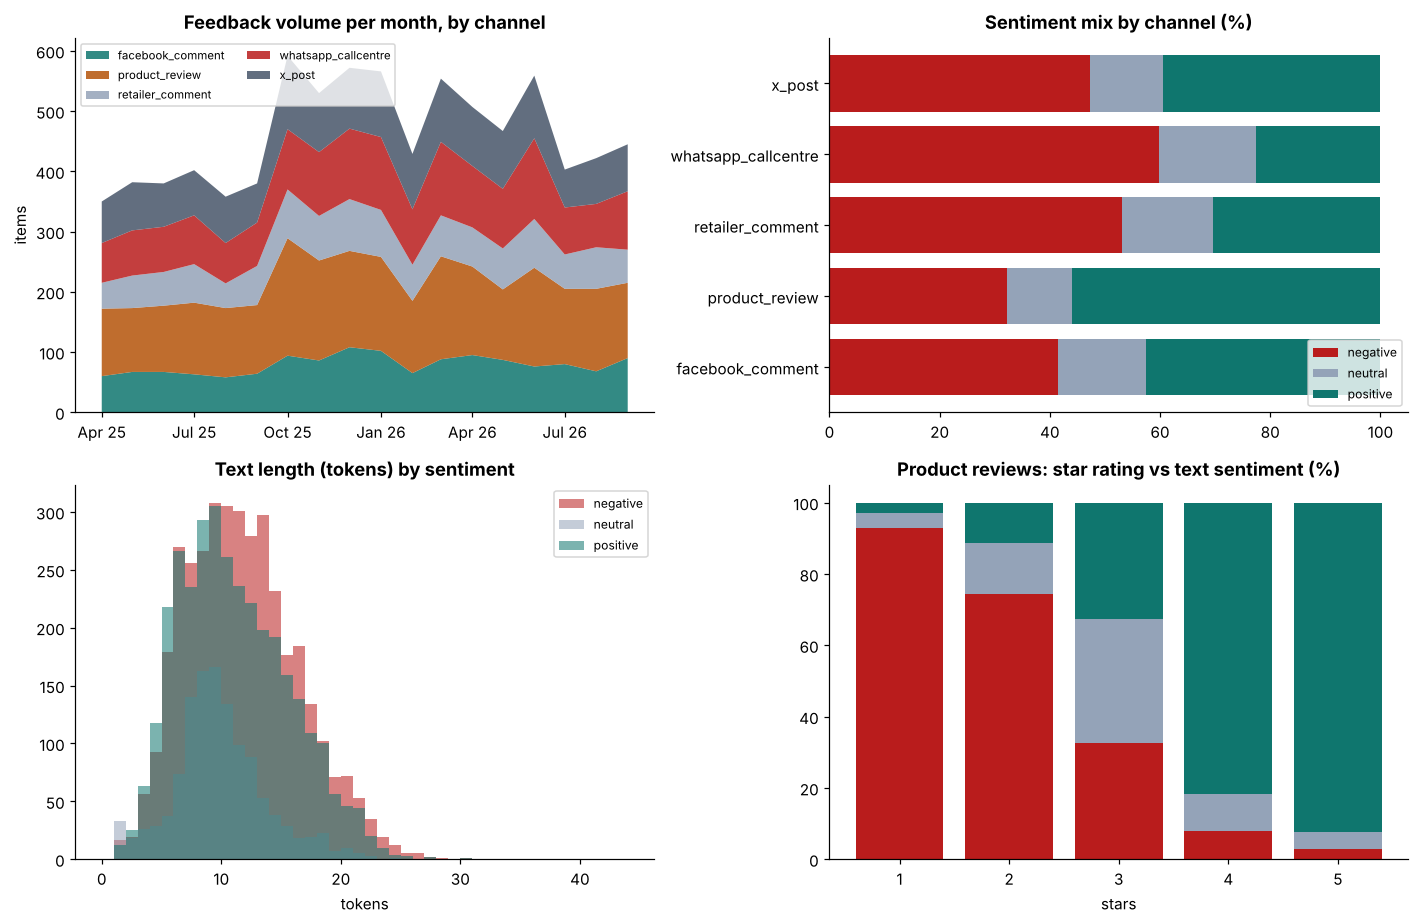

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
# (a) monthly volume by channel
vol = df.groupby(["month", "channel"]).size().unstack(fill_value=0)
vol.index = vol.index.to_timestamp()
cols = [TEAL, AMBER, GREY, RED, "#475569"]
ax[0, 0].stackplot(vol.index, vol.T.values, labels=vol.columns, colors=cols, alpha=.85)
ax[0, 0].set_title("Feedback volume per month, by channel"); ax[0, 0].legend(fontsize=7.5, loc="upper left", ncol=2)
ax[0, 0].set_ylabel("items")
ax[0, 0].xaxis.set_major_locator(__import__("matplotlib.dates", fromlist=["x"]).MonthLocator(bymonth=[1, 4, 7, 10]))
ax[0, 0].xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["x"]).DateFormatter("%b %y"))
# (b) label mix by channel
mix = pd.crosstab(df.channel, df.sentiment, normalize="index")[LABELS] * 100
left = np.zeros(len(mix))
for lab in LABELS:
    ax[0, 1].barh(mix.index, mix[lab], left=left, color=LAB_COL[lab], label=lab); left += mix[lab].values
ax[0, 1].set_title("Sentiment mix by channel (%)"); ax[0, 1].legend(fontsize=8, loc="lower right")
# (c) text length by label
for lab in LABELS:
    ax[1, 0].hist(df.loc[df.sentiment == lab, "n_tokens"], bins=range(0, 45), alpha=.55, color=LAB_COL[lab], label=lab)
ax[1, 0].set_title("Text length (tokens) by sentiment"); ax[1, 0].set_xlabel("tokens"); ax[1, 0].legend(fontsize=8)
# (d) star rating vs gold label (product reviews only)
rv = pd.crosstab(df.loc[df.channel == "product_review", "rating"].astype(int),
                 df.loc[df.channel == "product_review", "sentiment"], normalize="index")[LABELS] * 100
bottom = np.zeros(len(rv))
for lab in LABELS:
    ax[1, 1].bar(rv.index.astype(str), rv[lab], bottom=bottom, color=LAB_COL[lab], label=lab); bottom += rv[lab].values
ax[1, 1].set_title("Product reviews: star rating vs text sentiment (%)"); ax[1, 1].set_xlabel("stars")
plt.tight_layout(); plt.savefig(OUT / "01_eda_overview.png", dpi=130, bbox_inches="tight"); plt.show()

In [8]:
print("Median tokens by channel:", df.groupby("channel").n_tokens.median().to_dict())
rv_tab = pd.crosstab(df.loc[df.channel == "product_review", "rating"].astype(int),
                     df.loc[df.channel == "product_review", "sentiment"], margins=True)
display(rv_tab)
r = df.loc[df.channel == "product_review"]
agree = ((r.rating >= 4) & (r.sentiment == "positive")) | ((r.rating <= 2) & (r.sentiment == "negative")) | \
        ((r.rating == 3) & (r.sentiment == "neutral"))
print(f"Star rating 'agrees' with text label for {agree.mean():.1%} of reviews")

Median tokens by channel: {'facebook_comment': 9.0, 'product_review': 11.0, 'retailer_comment': 11.0, 'whatsapp_callcentre': 10.0, 'x_post': 10.0}


sentiment,negative,neutral,positive,All
rating,,,,
1,353,16,11,380
2,252,49,38,339
3,119,126,119,364
4,47,62,486,595
5,23,36,722,781
All,794,289,1376,2459


Star rating 'agrees' with text label for 78.9% of reviews


**Interpretation**

* **Volume** averages about 460 items a month (roughly 350–590), with visible **bumps** in October–December 2025, January and March 2026 and June 2026. Those bumps are the first sign of the hidden events. Complaints arrive in bursts when something goes wrong.
* **Texts are short**: a median of 9–11 tokens depending on channel, as expected for tweets and WhatsApp messages. Short texts give a model little context, which is one reason sarcasm and mixed sentiment are hard.
* **Star ratings and text sentiment mostly agree, but not always** (79% agreement). 1–2-star reviews are overwhelmingly negative and 4–5 stars positive, but 3-star reviews are spread across all three classes. Many of them are *mixed* ("love the taste but too expensive"). **A rating is not a substitute for reading the text.** The rating also exists only for product reviews. The other channels, about 70% of the volume, have no rating at all, which is why we need a text model.

## 5. Train / test split: a time-based split

We train on **April 2025 – May 2026** and test on the **last four months (June – September 2026)**.

Why not a random split? In production, a model trained on past feedback scores **future** feedback, where new products, new slang and new problems appear. A time-based split tests exactly that, and it is stricter than a random split. For example, the June 2026 cold-chain incident in the Coast region falls entirely in the test period.

All tuning (hyper-parameters, lexicon thresholds) uses **only the training period**, with 5-fold stratified cross-validation inside it. The test set is used once, at the end.

In [9]:
SPLIT = pd.Timestamp("2026-06-01")
train, test = df[df.date < SPLIT].copy(), df[df.date >= SPLIT].copy()
split_tab = pd.DataFrame({"items": [len(train), len(test)],
                          "period": [f"{train.date.min():%b %Y} - {train.date.max():%b %Y}", f"{test.date.min():%b %Y} - {test.date.max():%b %Y}"]},
                         index=["train", "test"]).join(pd.concat([train.sentiment.value_counts(normalize=True).rename("train"),
                                                                  test.sentiment.value_counts(normalize=True).rename("test")], axis=1).T.round(3))
split_tab

,items,period,negative,positive,neutral
train,6469,Apr 2025 - May 2026,0.451,0.405,0.144
test,1829,Jun 2026 - Sep 2026,0.455,0.390,0.155


---
# METHOD 1 — Lexicon-based sentiment (VADER)

## 6. How VADER works

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) needs no training data. It uses a dictionary of about 7,500 words, each with a human-rated **valence** from −4 (very negative) to +4 (very positive), plus rules for the things people do in short informal texts:

* **Negation:** "not good" flips and dampens "good" (a valence of 1.9 multiplied by −0.74).
* **Boosters / dampeners:** "very", "extremely" and "kind of" raise or lower the next word.
* **"But":** words after "but" count more (×1.5) and words before it count less (×0.5).
* **Capitals and "!!!":** "GOOD!!!" counts more than "good".
* **Emojis:** converted to their names ("smiling face with heart-eyes") and scored.

The valences are summed and squashed into the **compound score**, which runs from −1 to +1:

$$\text{compound} = \frac{x}{\sqrt{x^2 + 15}}, \quad x = \text{sum of adjusted valences}$$

The standard decision rule: **compound ≥ 0.05 → positive, ≤ −0.05 → negative, otherwise neutral.**

**Why use a lexicon at all?** It's transparent (you can see exactly which words drove a score), it needs no labelled data, and it's a strong baseline. Its weakness is that it only knows the words in its dictionary. VADER was built on American English social media, and it has never seen *imeharibika*, *bei iko juu* or even *expired*.

## 7. Extending the lexicon for Kenyan dairy feedback

The **extended lexicon** makes three changes:

1. **Translate** Kiswahili, Sheng and slang with the normalisation dictionary from Section 3.
2. **Mask product names** ("fresh milk" → "product"). Otherwise the product *fresh milk* looks positive in a neutral question such as "Is the fresh milk available in Kisumu?"
3. **Add 52 dairy-specific words** (45 of them unknown to VADER) with hand-set valences: *expired* (−2.3), *curdled* (−2.5), *leaking* (−2.0), *overpriced* (−2.2), *unavailable* (−1.8), *creamy* (+1.8), *affordable* (+1.8), *punctual* (+1.6), etc. Multi-word phrases are collapsed first ("out of stock" → *unavailable*, "gone bad" → *spoiled*).

In [10]:
vader = SentimentIntensityAnalyzer()
ext = tu.extended_analyzer()
print(f"Domain words added: {len(tu.DOMAIN_LEXICON)} | of which NOT in the original VADER lexicon: "
      f"{sum(w not in vader.lexicon for w in tu.DOMAIN_LEXICON)}")
for d in (train, test):
    d["vader_compound"] = d.text.map(lambda t: vader.polarity_scores(t)["compound"])
    d["ext_compound"] = d.text.map(lambda t: ext.polarity_scores(tu.lexicon_text(t))["compound"])
    d["vader_pred"] = d.vader_compound.map(tu.to_label)
    d["ext_pred"] = d.ext_compound.map(tu.to_label)

# Thresholds tuned on the TRAINING period only (a fair, cheap improvement)
grid = [(p, n) for p in np.arange(.05, .61, .05) for n in np.arange(-.05, -.61, -.05)]
def tune(col):
    sc = [(f1_score(train.sentiment, train[col].map(lambda c: tu.to_label(c, p, n)), average="macro"), p, n) for p, n in grid]
    return max(sc)
best_v, best_e = tune("vader_compound"), tune("ext_compound")
print(f"Tuned thresholds  VADER: pos >= {best_v[1]:.2f}, neg <= {best_v[2]:.2f} | "
      f"Extended: pos >= {best_e[1]:.2f}, neg <= {best_e[2]:.2f}")
for d in (train, test):
    d["vader_tuned_pred"] = d.vader_compound.map(lambda c: tu.to_label(c, best_v[1], best_v[2]))
    d["ext_tuned_pred"] = d.ext_compound.map(lambda c: tu.to_label(c, best_e[1], best_e[2]))

def scores(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=LABELS, zero_division=0)
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
            **{f"F1_{l[:3]}": f for l, f in zip(LABELS, f1)}}
lex_res = pd.DataFrame({name: scores(test.sentiment, test[col]) for name, col in
                        [("VADER (default ±0.05)", "vader_pred"), ("VADER (tuned thresholds)", "vader_tuned_pred"),
                         ("Extended lexicon (default ±0.05)", "ext_pred"), ("Extended lexicon (tuned)", "ext_tuned_pred")]}).T.round(3)
lex_res

Domain words added: 52 | of which NOT in the original VADER lexicon: 45


Tuned thresholds  VADER: pos >= 0.10, neg <= -0.05 | Extended: pos >= 0.10, neg <= -0.05


,accuracy,macro_f1,F1_neg,F1_neu,F1_pos
VADER (default ±0.05),0.492,0.456,0.409,0.314,0.645
VADER (tuned thresholds),0.495,0.462,0.409,0.329,0.649
Extended lexicon (default ±0.05),0.694,0.643,0.741,0.447,0.742
Extended lexicon (tuned),0.695,0.648,0.741,0.461,0.743


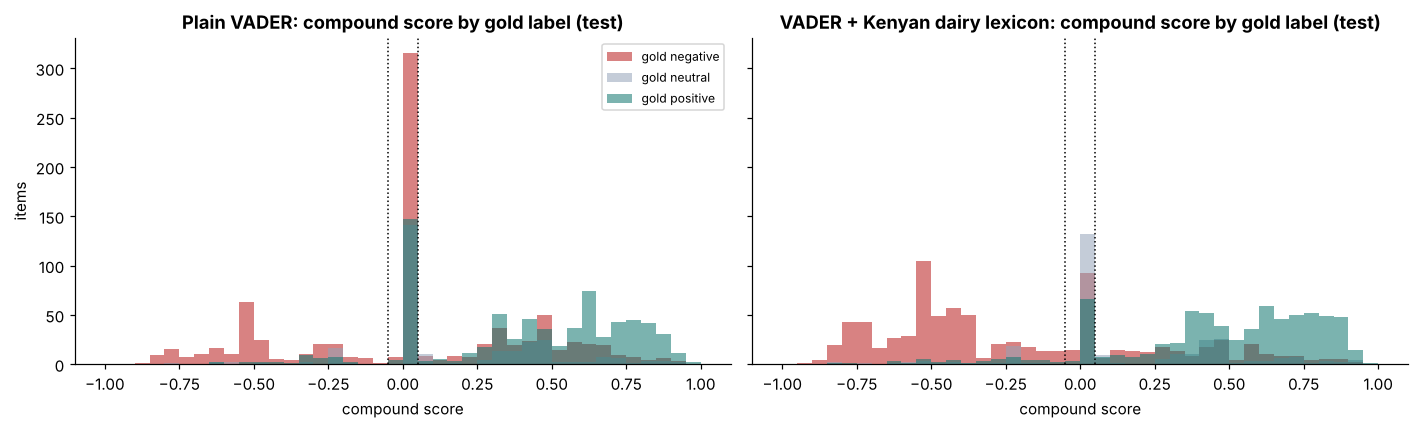

Share of test items with compound exactly 0 (no known sentiment word): VADER 32.7% -> extended 15.4%


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, col, title in [(ax[0], "vader_compound", "Plain VADER"), (ax[1], "ext_compound", "VADER + Kenyan dairy lexicon")]:
    for lab in LABELS:
        a.hist(test.loc[test.sentiment == lab, col], bins=np.linspace(-1, 1, 41), alpha=.55, color=LAB_COL[lab], label=f"gold {lab}")
    a.axvline(.05, color="k", ls=":", lw=1); a.axvline(-.05, color="k", ls=":", lw=1)
    a.set_title(f"{title}: compound score by gold label (test)"); a.set_xlabel("compound score")
ax[0].legend(fontsize=8); ax[0].set_ylabel("items")
plt.tight_layout(); plt.savefig(OUT / "02_lexicon_compound.png", dpi=130, bbox_inches="tight"); plt.show()
zero_v = (test.vader_compound == 0).mean(); zero_e = (test.ext_compound == 0).mean()
print(f"Share of test items with compound exactly 0 (no known sentiment word): VADER {zero_v:.1%} -> extended {zero_e:.1%}")

In [12]:
# Where did the domain lexicon flip a wrong answer into a right one (and vice versa)?
fixed = test[(test.vader_pred != test.sentiment) & (test.ext_pred == test.sentiment)]
broke = test[(test.vader_pred == test.sentiment) & (test.ext_pred != test.sentiment)]
print(f"Extended lexicon fixed {len(fixed)} test items and broke {len(broke)}.")
display(fixed.sample(8, random_state=1)[["text", "sentiment", "vader_compound", "ext_compound"]])
display(broke.sample(5, random_state=1)[["text", "sentiment", "vader_compound", "ext_compound"]])

Extended lexicon fixed 405 test items and broke 35.


,text,sentiment,vader_compound,ext_compound
8097,Not expensive at all,positive,0.0000,0.2924
6710,Bought the strawberry yoghurt last week. Mould on the lid of the strawberry yoghurt.,negative,0.0000,-0.4588
7892,Been buying Maziwa Bora for years. MAZIWA IMEGANDA KABLA YA EXPIRY.,negative,0.0000,-0.5423
6830,Outlet feedback: Maziwa imeharibika Mombasa wiki hii,negative,0.0000,-0.5106
7014,Merchandiser note: The milk curdled before the expiry date and out of stock everywhere.,negative,0.0000,-0.7430
7750,"Review: Nice packaging, however ladha imebadilika, sio kama zamani.",negative,0.4215,-0.0772
7423,Smelt sour on opening and overpriced for what you get.,negative,0.0000,-0.6908
7772,Tried the yoghurt. The yoghurt tastes very sour.,negative,0.0000,-0.4201


,text,sentiment,vader_compound,ext_compound
7048,"Tried the fresh milk. Long shelf life, even though out of stock everywhere Would buy again.",positive,0.3182,-0.4215
7505,"Good morning, lala haipatikani Kasarani.",positive,0.4404,0.0258
6612,"Hello Maziwa Bora, expired stock at the shops in Diani. Also doesn't taste like real milk. Never again. 😠",positive,0.1511,-0.4035
8111,"Habari, although tumekosa stock ya queen cakes, the queen cakes are soft and fresh. Batch no. MB16423. 🙌👍",positive,0.3182,-0.0516
8169,"Habari, the 1L long-life milk curdled when I boiled it. the 1L long-life milk tastes sour Kindly call back.",positive,0.4939,-0.4215


**Interpretation: how much does the domain lexicon help?**

* **Plain VADER is weak on this data: macro-F1 0.456 and accuracy 49%.** The main reason is shown in the left chart: **a third of test items (32.7%) get a compound score of exactly 0**, because VADER knows none of their words. "Maziwa imeharibika", "out of stock everywhere" and "overpriced for what you get" all score zero, so most complaints land in *neutral*. VADER finds only **28% of negative items** (recall 0.275). It does better on positive feedback, because praise uses standard English words ("great", "nice", "love").
* **The domain lexicon helps a lot: macro-F1 rises from 0.456 to 0.643 (+0.19)**, accuracy from 49% to 69%, and negative recall from 0.28 to 0.64. The share of zero-score items halves (32.7% → 15.4%). On the test set the extended lexicon **fixed 405 items and broke 35**. Almost all of the gains come from Kiswahili/Sheng translation and dairy words (*curdled, expired, leaking, unavailable*).
* **Tuning the thresholds on the training data barely matters** (+0.005 to +0.006). The problem is missing vocabulary, not where the cut-offs sit.
* **What the lexicon still cannot do:** (1) **sarcasm**: "Great, another expired yoghurt 🙄" still scores positive because of "great"; (2) **neutral questions**: neutral F1 is only 0.46; (3) **mixed sentences**: VADER's built-in "but" rule helps, but it doesn't know that "even though" or "lakini" also mark the less important clause. Several of the 35 "broken" items are mixed sentences or noisy gold labels.

**Verdict:** a domain lexicon is a large, cheap upgrade over off-the-shelf VADER, and it stays fully transparent. But a 0.64 macro-F1 is not good enough to drive alerts on its own.

---
# METHOD 2 — Classical machine learning (TF-IDF + linear models)

## 8. Turning text into features: TF-IDF

A model needs numbers, not words. **TF-IDF** (term frequency × inverse document frequency) represents each text as a long, sparse vector with one column per n-gram:

* **TF:** how often the n-gram appears in this text (we use `sublinear_tf`, i.e. 1 + log(tf), so repeating a word ten times doesn't count ten times as much).
* **IDF:** down-weights n-grams that appear everywhere ("the", "brandtoken") and up-weights distinctive ones ("curdled", "inavuja").
* Each vector is L2-normalised, so long and short texts are comparable.

We combine **two feature sets** with a `FeatureUnion`:

| Features | Example | What it captures |
|---|---|---|
| **Word 1–2-grams** | `fresh`, `not fresh`, `bei iko`, `iko juu` | Vocabulary **and** short phrases. The bigram `not fresh` is how a linear model learns negation. |
| **Character 2–5-grams** (within word boundaries) | `exp`, `xpir`, `vuja` | Robust to **typos** ("expred"), Kiswahili **morphology** (*imeharibika*, *kuharibika* share *harib*) and Sheng spelling variants |

## 9. Three classic text classifiers

| Model | Idea | Strength | Weakness |
|---|---|---|---|
| **Multinomial Naive Bayes** | Probability of each word given the class, assuming words are independent | Very fast, strong with little data | The independence assumption is wrong for phrases; probabilities are over-confident |
| **Logistic Regression** | A weighted sum of features → softmax probabilities | Calibrated probabilities, **interpretable weights** | Linear: cannot model interactions such as "great" + 🙄 |
| **Linear SVM** | Finds the maximum-margin boundary between classes | Often the most accurate on sparse text | No probabilities (needs calibration), less interpretable |

Hyper-parameters are tuned by **5-fold stratified cross-validation on the training period**, optimising **macro-F1**. Macro-F1 averages F1 over the three classes equally, so the small **neutral** class counts as much as the large ones. Accuracy would reward a model that ignores it. We also try `class_weight="balanced"`, which up-weights the minority neutral class.

In [13]:
def features():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b[\w']+\b")),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=60000)),
    ])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=4000, random_state=SEED),
                            {"clf__C": [2, 8, 32], "clf__class_weight": [None, "balanced"]}),
    "Linear SVM": (LinearSVC(random_state=SEED), {"clf__C": [0.1, 0.3, 1.0], "clf__class_weight": [None, "balanced"]}),
    "Multinomial NB": (MultinomialNB(), {"clf__alpha": [0.02, 0.05, 0.2]}),
}
searches, cv_rows = {}, []
for name, (clf, grid_) in search_space.items():
    t0 = time.time()
    gs = GridSearchCV(Pipeline([("feats", features()), ("clf", clf)]), grid_, scoring="f1_macro", cv=cv, n_jobs=-1)
    gs.fit(train.clean, train.sentiment)
    searches[name] = gs
    cv_rows.append({"model": name, "best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                    "CV macro-F1 (mean)": round(gs.best_score_, 3),
                    "CV macro-F1 (sd)": round(gs.cv_results_["std_test_score"][gs.best_index_], 3),
                    "minutes": round((time.time() - t0) / 60, 1)})
cv_table = pd.DataFrame(cv_rows).set_index("model"); cv_table

,best params,CV macro-F1 (mean),CV macro-F1 (sd),minutes
model,,,,
Logistic Regression,"{'C': 2, 'class_weight': None}",0.874,0.006,0.4
Linear SVM,"{'C': 0.3, 'class_weight': None}",0.880,0.006,0.2
Multinomial NB,{'alpha': 0.02},0.852,0.006,0.1


## 10. Do the design choices matter? A small ablation

Before trusting the full feature set, we check what each ingredient adds, using the tuned Logistic Regression and the same 5-fold CV on the training period:

In [14]:
lr_params = {k.replace("clf__", ""): v for k, v in searches["Logistic Regression"].best_params_.items()}
def lr_pipe(feats):
    return Pipeline([("feats", feats), ("clf", LogisticRegression(max_iter=4000, random_state=SEED, **lr_params))])
word_only = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b[\w']+\b")
uni_only = TfidfVectorizer(ngram_range=(1, 1), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b[\w']+\b")
ablation = {}
for name, pipe, X in [("word unigrams only", lr_pipe(uni_only), train.clean),
                      ("word 1-2-grams", lr_pipe(word_only), train.clean),
                      ("word 1-2-grams + char 2-5-grams", lr_pipe(features()), train.clean),
                      ("  ... + Swahili/Sheng normalisation", lr_pipe(features()), train.clean_sw)]:
    s = pd.Series(cross_val_predict(pipe, X, train.sentiment, cv=cv, n_jobs=-1), index=train.index)
    cs = train.hard_case_tags.str.contains("code_switch")
    ablation[name] = {"CV macro-F1": f1_score(train.sentiment, s, average="macro"),
                      "CV macro-F1 on code-switched items": f1_score(train.sentiment[cs], s[cs], average="macro"),
                      "CV macro-F1 on negation items": f1_score(train.sentiment[train.hard_case_tags.str.contains("negation")],
                                                                s[train.hard_case_tags.str.contains("negation")], average="macro")}
ablation = pd.DataFrame(ablation).T.round(3); ablation

,CV macro-F1,CV macro-F1 on code-switched items,CV macro-F1 on negation items
word unigrams only,0.866,0.797,0.821
word 1-2-grams,0.870,0.804,0.834
word 1-2-grams + char 2-5-grams,0.874,0.812,0.839
... + Swahili/Sheng normalisation,0.875,0.811,0.842


**Interpretation**

* **Bigrams are how a linear model learns negation.** Moving from unigrams to 1–2-grams lifts CV macro-F1 on negation items from 0.821 to 0.834: `not fresh` and `not bad` become features in their own right.
* **Character n-grams help with code-switching and typos** (code-switched items 0.804 → 0.812; overall 0.870 → 0.874).
* **Kiswahili/Sheng normalisation adds almost nothing for the ML model** (0.874 → 0.875, well inside the CV standard deviation of about 0.006). This is an honest and useful finding. A supervised model **learns** that *imeharibika* is negative directly from labelled examples, so translating it first is redundant. For the lexicon, which has no training data, the same dictionary was essential (+0.19 macro-F1). **Domain knowledge matters most where there is no labelled data.**
* All gains are small in absolute terms, because word unigrams alone already reach 0.866. The final models use word 1–2-grams plus character 2–5-grams on the cleaned (not translated) text.

---
# METHOD 3 — A simple ensemble

Different models make different mistakes. A **soft-voting ensemble** averages the class probabilities of Logistic Regression, a calibrated Linear SVM (Platt scaling via `CalibratedClassifierCV`, because the SVM has no probabilities of its own) and Naive Bayes, each with its tuned settings. If the errors are not perfectly correlated, the average should be at least as good as the best single model.

In [15]:
best_est = {n: s.best_estimator_ for n, s in searches.items()}
svm_params = {k.replace("clf__", ""): v for k, v in searches["Linear SVM"].best_params_.items()}
nb_params = {k.replace("clf__", ""): v for k, v in searches["Multinomial NB"].best_params_.items()}
ensemble = Pipeline([("feats", features()), ("clf", VotingClassifier([
    ("lr", LogisticRegression(max_iter=4000, random_state=SEED, **lr_params)),
    ("svm", CalibratedClassifierCV(LinearSVC(random_state=SEED, **svm_params), cv=3)),
    ("nb", MultinomialNB(**nb_params))], voting="soft"))])
ensemble.fit(train.clean, train.sentiment)
best_est["Soft-voting ensemble"] = ensemble
for n, m in best_est.items():
    test[f"pred_{n}"] = m.predict(test.clean)
print("Fitted:", list(best_est))

Fitted: ['Logistic Regression', 'Linear SVM', 'Multinomial NB', 'Soft-voting ensemble']


---
## 11. Evaluation on the held-out test period (June – September 2026)

Each method is scored once on the four test months. We report:

* **Accuracy:** the share of items labelled correctly. Easy to read, but flattered by the big classes.
* **Macro-F1:** our headline metric. F1 is the harmonic mean of precision and recall, averaged equally over the three classes.
* **Per-class precision / recall.** *Precision* (negative): of the items we flag as negative, how many really are? This decides whether alerts can be trusted. *Recall* (negative): of all the truly negative items, how many did we catch? This decides whether problems slip through.
* **A 95% bootstrap confidence interval** for macro-F1: we resample the test set 1,000 times. Four months of data is a sample, and the interval shows how much the score could move on another sample.

In [16]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(test), len(test)) for _ in range(1000)]
def boot_ci(y, p):
    y, p = np.asarray(y), np.asarray(p)
    s = [f1_score(y[i], p[i], average="macro") for i in boot_idx]
    return np.percentile(s, [2.5, 97.5])
methods = [("VADER", "vader_pred"), ("VADER (tuned)", "vader_tuned_pred"), ("Extended lexicon", "ext_pred"),
           ("Extended lexicon (tuned)", "ext_tuned_pred")] + [(n, f"pred_{n}") for n in best_est]
rows = []
for name, col in methods:
    s = scores(test.sentiment, test[col]); lo, hi = boot_ci(test.sentiment, test[col])
    pr, rc, _, _ = precision_recall_fscore_support(test.sentiment, test[col], labels=LABELS, zero_division=0)
    rows.append({"method": name, "family": "lexicon" if "lexicon" in name.lower() or "VADER" in name else "ML",
                 "accuracy": s["accuracy"], "macro_F1": s["macro_f1"], "F1 95% CI": f"{lo:.3f}-{hi:.3f}",
                 "prec_neg": pr[0], "rec_neg": rc[0], "prec_neu": pr[1], "rec_neu": rc[1], "prec_pos": pr[2], "rec_pos": rc[2]})
comparison = pd.DataFrame(rows).set_index("method").round(3).sort_values("macro_F1", ascending=False)
comparison.to_csv(OUT / "model_comparison.csv")
BEST = comparison[comparison.family == "ML"].index[0]
print("Best ML model on the test period:", BEST)
comparison

Best ML model on the test period: Linear SVM


,family,accuracy,macro_F1,F1 95% CI,prec_neg,rec_neg,prec_neu,rec_neu,prec_pos,rec_pos
method,,,,,,,,,,
Linear SVM,ML,0.909,0.889,0.873-0.905,0.924,0.936,0.879,0.767,0.902,0.934
Logistic Regression,ML,0.905,0.884,0.867-0.901,0.925,0.934,0.864,0.763,0.897,0.928
Soft-voting ensemble,ML,0.891,0.871,0.853-0.887,0.911,0.922,0.829,0.770,0.891,0.903
Multinomial NB,ML,0.873,0.853,0.833-0.870,0.898,0.903,0.783,0.777,0.879,0.877
Extended lexicon (tuned),lexicon,0.695,0.648,0.625-0.673,0.873,0.643,0.429,0.498,0.670,0.833
Extended lexicon,lexicon,0.694,0.643,0.621-0.666,0.873,0.643,0.430,0.466,0.662,0.843
VADER (tuned),lexicon,0.495,0.462,0.441-0.485,0.798,0.275,0.238,0.534,0.580,0.738
VADER,lexicon,0.492,0.456,0.435-0.479,0.798,0.275,0.230,0.498,0.570,0.742


              precision    recall  f1-score   support

    negative      0.924     0.936     0.930       833
     neutral      0.879     0.767     0.819       283
    positive      0.902     0.934     0.918       713

    accuracy                          0.909      1829
   macro avg      0.902     0.879     0.889      1829
weighted avg      0.909     0.909     0.908      1829



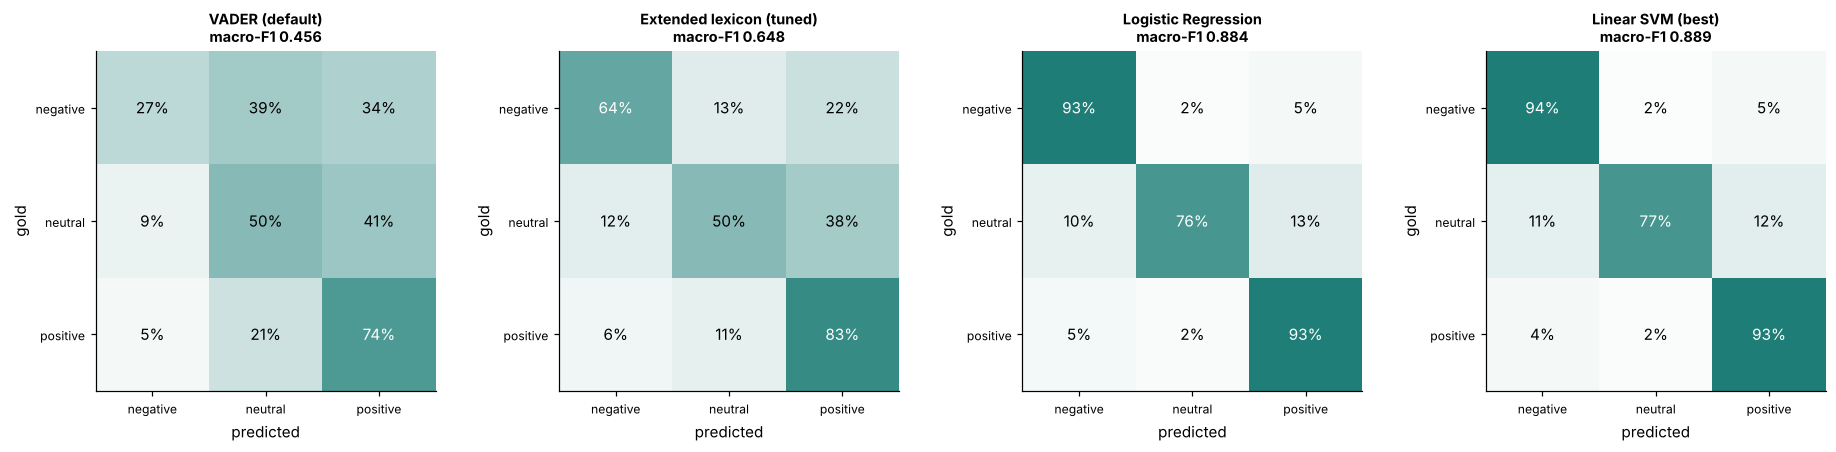

In [17]:
print(classification_report(test.sentiment, test[f"pred_{BEST}"], digits=3))
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, (name, col) in zip(ax, [("VADER (default)", "vader_pred"), ("Extended lexicon (tuned)", "ext_tuned_pred"),
                               ("Logistic Regression", "pred_Logistic Regression"), (BEST + " (best)", f"pred_{BEST}")]):
    cm = confusion_matrix(test.sentiment, test[col], labels=LABELS, normalize="true")
    a.imshow(cm, cmap=TEAL_CMAP, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            a.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > .55 else "black", fontsize=10)
    a.set_xticks(range(3), LABELS, fontsize=8); a.set_yticks(range(3), LABELS, fontsize=8)
    a.set_xlabel("predicted"); a.set_ylabel("gold")
    a.set_title(f"{name}\nmacro-F1 {f1_score(test.sentiment, test[col], average='macro'):.3f}", fontsize=9.5)
plt.tight_layout(); plt.savefig(OUT / "04_confusion_matrices.png", dpi=130, bbox_inches="tight"); plt.show()

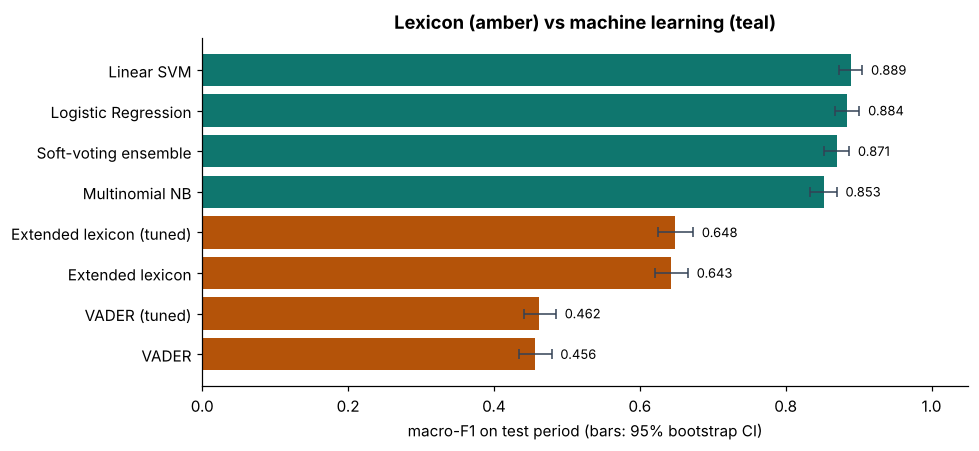

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
c = comparison.sort_values("macro_F1")
lo_hi = c["F1 95% CI"].str.split("-", expand=True).astype(float)
ax.barh(c.index, c.macro_F1, color=[TEAL if f == "ML" else AMBER for f in c.family],
        xerr=[c.macro_F1 - lo_hi[0], lo_hi[1] - c.macro_F1], capsize=3, error_kw={"lw": 1, "ecolor": "#334155"})
for i, (v, h) in enumerate(zip(c.macro_F1, lo_hi[1])):
    ax.text(h + .012, i, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlim(0, 1.05); ax.set_xlabel("macro-F1 on test period (bars: 95% bootstrap CI)")
ax.set_title("Lexicon (amber) vs machine learning (teal)")
plt.tight_layout(); plt.savefig(OUT / "03_model_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

**Interpretation**

* **Machine learning beats the lexicons by a wide margin.** The best model, a **Linear SVM**, reaches **macro-F1 0.889 (95% CI 0.873–0.905)** and **91% accuracy** on four months it never saw, against 0.648 for the best lexicon and 0.456 for plain VADER.
* **Linear SVM and Logistic Regression are effectively tied** (0.889 vs 0.884, overlapping confidence intervals). Naive Bayes is clearly weaker (0.853). The cross-validated estimates on the training period (0.880 and 0.874) are close to the test scores, so the models are not overfitting, and the time-based split shows **no drift** over these four months.
* **The ensemble did not help** (0.871, below both linear models). The three models make highly correlated errors, and averaging in the weaker Naive Bayes pulls the result down. More models do not automatically mean a better result.
* **Neutral is the hardest class** (recall 0.77). The confusion matrix shows neutral items leaking both ways: 11% are predicted negative and 12% positive. Many neutral items are questions or information that sit next to an emotional sign-off ("…Kindly advise").
* **The ceiling is below 100% by design.** About 5% of gold labels were deliberately flipped and about 3% of items are ambiguous, so a perfect model would still score only around 95% accuracy against these labels. The remaining 9% error is therefore partly label noise rather than model error.
* For **alerting**, negative precision (0.92) and recall (0.94) are the numbers that matter: about 92% of what the model flags as negative is truly negative, and it catches about 94% of all negative feedback.

## 12. Explainability: which n-grams drive the predictions?

Logistic Regression has one weight per feature per class. A large positive weight for the *negative* class means "this n-gram pushes a text towards negative". The chart shows the strongest **word** n-grams for the negative and positive classes. Character n-grams are left out because fragments such as `xpir` are hard to read.

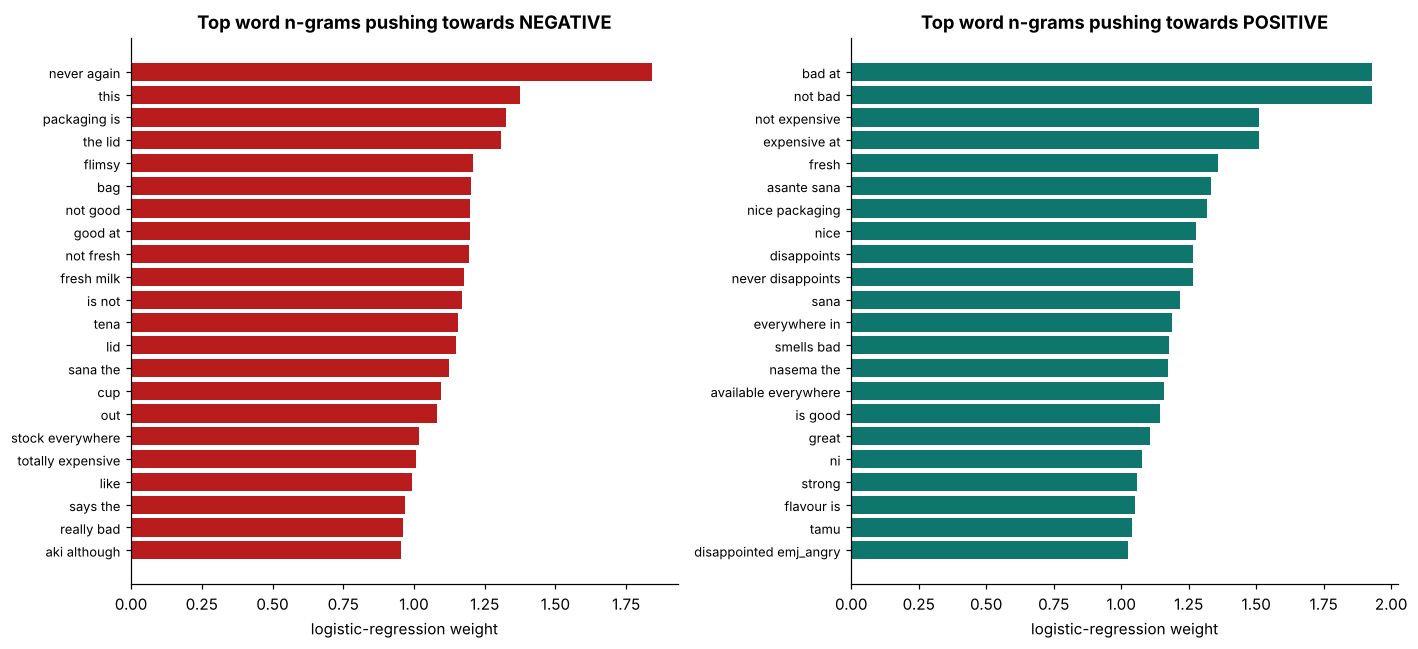

,negative,positive,neutral
0,never again,bad at,is the
1,this,not bad,sana keep
2,packaging is,not expensive,just bought
3,the lid,expensive at,disappointed emj_sad
4,flimsy,fresh,emj_eyes
5,bag,asante sana,emj_sad emj_angry
6,not good,nice packaging,tasty emj_ok
7,good at,nice,not sure
8,not fresh,disappoints,just
9,fresh milk,never disappoints,do you


In [19]:
lr = best_est["Logistic Regression"]
wvec = lr.named_steps["feats"].transformer_list[0][1]
n_word = len(wvec.vocabulary_)
names = np.array(wvec.get_feature_names_out())
coef = lr.named_steps["clf"].coef_
cls = list(lr.named_steps["clf"].classes_)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
top_tables = {}
for a, lab, col in [(ax[0], "negative", RED), (ax[1], "positive", TEAL)]:
    w = coef[cls.index(lab), :n_word]
    idx = np.argsort(w)[-22:]
    a.barh(names[idx], w[idx], color=col); a.set_title(f"Top word n-grams pushing towards {lab.upper()}")
    a.tick_params(axis="y", labelsize=8.5); a.set_xlabel("logistic-regression weight")
    top_tables[lab] = list(names[np.argsort(w)[::-1][:25]])
plt.tight_layout(); plt.savefig(OUT / "05_top_ngrams.png", dpi=130, bbox_inches="tight"); plt.show()
w_neu = coef[cls.index("neutral"), :n_word]
top_tables["neutral"] = list(names[np.argsort(w_neu)[::-1][:25]])
pd.DataFrame(top_tables)

**Interpretation**

* **The model has learned negation from bigrams.** The strongest *positive* features are `bad at` and `not bad` (from "not bad at all"), and `not expensive` / `expensive at` (from "not expensive at all"). On the negative side, `not good`, `not fresh` and `is not` appear. A unigram model would have read "bad" and "expensive" the wrong way round.
* **Dairy problems drive negative predictions:** `the lid`, `flimsy`, `packaging is`, `cup`, `stock everywhere`, `inavuja` (leaking) and `tena` (again, as in "bei imepanda tena", "delivery imechelewa tena"). **Kiswahili/Sheng drives positive predictions too:** `asante sana`, `sana`, `tamu`, `ni`.
* **Neutral** is driven by question and information words (`is the`, `just bought`, `do you`, `not sure`, `halal`, `ngapi` = "how much").
* **Warning signs of shortcut learning:** `says the` (from "Shop owner … says: The …") pushes towards negative because retailer comments are mostly complaints. That is a **channel artefact**, not sentiment. `fresh milk` is a negative feature because milk is the most complained-about product. And `smells bad` or `disappointed emj_angry` appear among the positive features, because in mixed sentences the gold label follows a positive main clause ("…, even though the milk smells bad"), and some are flipped labels. **Single weights should not be read as causal "drivers" of sentiment**; they are useful for spotting artefacts like these.

## 13. Error analysis by hard-case type

An overall score hides *where* a model fails. Our data carries **hard-case tags**: an annotation team would add tags like these during labelling. They let us measure the **error rate** on each type of difficult text for the three main approaches. The tags are used only to *describe* the errors; the models never see them.

In [20]:
tag_list = ["negation", "sarcasm", "mixed", "code_switch", "typo_slang", "emoji", "ambiguous"]
err_rows = []
for t in tag_list + ["(no hard-case tag)"]:
    m = test.hard_case_tags.str.contains(t) if t != "(no hard-case tag)" else (test.hard_case_tags == "")
    row = {"tag": t, "test items": int(m.sum())}
    for name, col in [("VADER", "vader_pred"), ("Extended lexicon", "ext_tuned_pred"), (BEST, f"pred_{BEST}")]:
        row[f"error % {name}"] = round(100 * (test.loc[m, col] != test.loc[m, "sentiment"]).mean(), 1)
    err_rows.append(row)
row = {"tag": "ALL test items", "test items": len(test)}
for name, col in [("VADER", "vader_pred"), ("Extended lexicon", "ext_tuned_pred"), (BEST, f"pred_{BEST}")]:
    row[f"error % {name}"] = round(100 * (test[col] != test.sentiment).mean(), 1)
err_rows.append(row)
hard = pd.DataFrame(err_rows).set_index("tag"); hard.to_csv(OUT / "hard_case_error_rates.csv")
hard

,test items,error % VADER,error % Extended lexicon,error % Linear SVM
tag,,,,
negation,290,55.5,40.3,8.3
sarcasm,45,97.8,97.8,6.7
mixed,214,55.1,40.7,27.1
code_switch,412,59.7,25.7,10.9
typo_slang,115,54.8,36.5,8.7
emoji,418,37.3,24.2,5.5
ambiguous,46,56.5,56.5,58.7
(no hard-case tag),720,47.9,26.8,5.4
ALL test items,1829,50.8,30.5,9.1


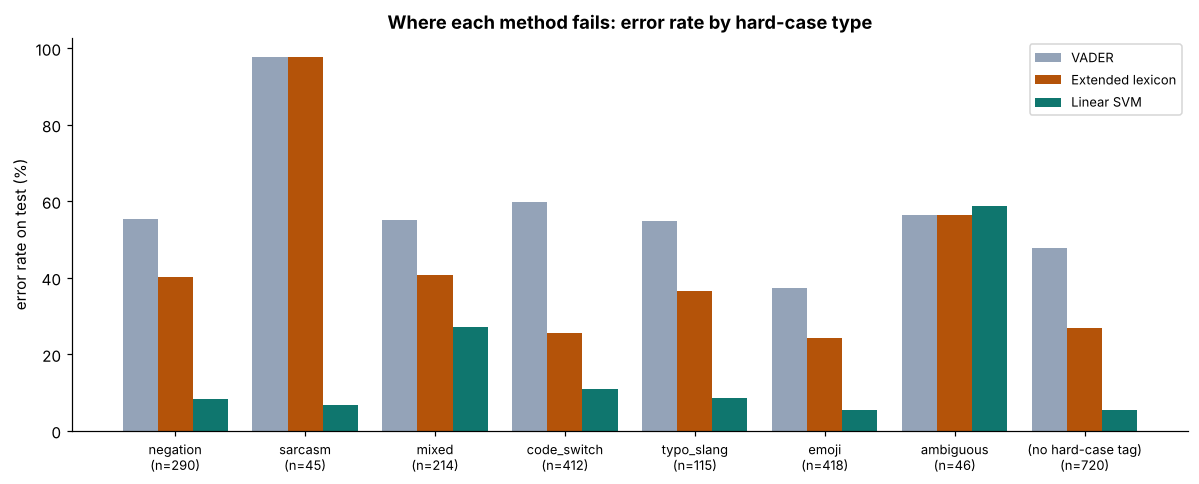

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))
h = hard.drop(index=["ALL test items"])
x = np.arange(len(h)); w = .27
for k, (col, c) in enumerate(zip(h.columns[1:], [GREY, AMBER, TEAL])):
    ax.bar(x + (k - 1) * w, h[col], w, color=c, label=col.replace("error % ", ""))
ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(h.index, h["test items"])], fontsize=8.5)
ax.set_ylabel("error rate on test (%)"); ax.legend(fontsize=8.5)
ax.set_title("Where each method fails: error rate by hard-case type")
plt.tight_layout(); plt.savefig(OUT / "06_hard_case_errors.png", dpi=130, bbox_inches="tight"); plt.show()

In [22]:
pred = f"pred_{BEST}"
wrong = test[test[pred] != test.sentiment]
for t in ["sarcasm", "mixed", "code_switch", "negation"]:
    ex = wrong[wrong.hard_case_tags.str.contains(t)]
    print(f"\n=== {t}: {len(ex)} errors by {BEST} — examples ===")
    for i, r in ex.sample(min(4, len(ex)), random_state=2).iterrows():
        print(f"  gold={r.sentiment:<8} pred={r[pred]:<8} | {r.text}")


=== sarcasm: 3 errors by Linear SVM — examples ===
  gold=neutral  pred=negative | Brilliant, the van came at 6pm when the shop was closing. 👏
  gold=neutral  pred=negative | Merchandiser note: Great job, empty shelves for the third week running
  gold=positive pred=negative | Hello MaziwaBora, great, another expired vanilla yoghurt. just what I needed

=== mixed: 58 errors by Linear SVM — examples ===
  gold=negative pred=positive | Hello customer care, long shelf life... but hii bread imekuwa mbaya sana. Never again.
  gold=positive pred=negative | Been buying MaziwaBora for years. Packaging is so flimsy but best 1L long-life milk I have ever had.
  gold=negative pred=positive | Shop owner in Westlands says: Lasts well past opening... but the straw is always missing
  gold=negative pred=positive | The offer price is super good... but Baobab Honey yoghurt inavuja kila mahali.

=== code_switch: 45 errors by Linear SVM — examples ===
  gold=positive pred=negative | Bought the smokies l

**Interpretation**

* **Every hard-case type is much easier for the ML model** than for either lexicon. Overall test error: VADER 50.8%, extended lexicon 30.5%, Linear SVM 9.1%.
* **Mixed sentiment is the ML model's biggest weakness (27.1% error, five times the 5.4% on untagged items).** A bag of n-grams sees the positive and the negative clause but has no notion of which one is the *main* clause. The examples show it: "long shelf life… but hii bread imekuwa mbaya sana" (gold negative, predicted positive). Contrast-aware features or a sequence model would be the next step.
* **Code-switching doubles the error rate** (10.9% vs 5.4% untagged), but it is no longer crippling. The extended lexicon's biggest gain was here: code-switched error fell from 59.7% (VADER) to 25.7%.
* **Negation** is handled reasonably well (8.3% error) thanks to bigrams. The lexicons still get 40–56% wrong.
* **Sarcasm defeats both lexicons completely (97.8% error)**, since the surface words are positive. The ML model gets only 3 of 45 wrong, and **all three are items whose gold label is itself wrong** (sarcastic complaints labelled neutral or positive by the simulated annotators). Treat this ML result with **heavy scepticism**: the generator uses a limited set of sarcasm templates, so the model can memorise them ("great job, empty shelves…"). Real sarcasm is far more varied, and on real data it would be one of the largest sources of error.
* **Ambiguous items** ("ok", "hmm 🤔") are wrong 56–59% of the time for every method, as expected. Their labels are close to a coin flip, so no method can do better.

---
## 14. Aspect-based sentiment: *what* are customers positive or negative about?

An overall label says *how* a customer feels. Operations teams need to know **about what**. "Negative" is not actionable; **"negative about packaging, on yoghurt, since October"** is.

**Approach (transparent and rule-based):**

1. **Split** each text into clauses at sentence punctuation, commas and contrast words (*but, however, although, though, also, lakini*).
2. **Detect aspects** in each clause with keyword / regex rules in English, Kiswahili and Sheng (e.g. packaging: `lid|seal|cup|packet|leak|kifuniko|vuja…`). Product names from the catalogue are masked first, so "500ml milk **packet**" does not count as a packaging comment.
3. **Score the sentiment of each clause** and give it to the aspects found in that clause. We compare two clause scorers: the **extended lexicon** and the **best ML model applied to the clause**.
4. **Evaluate** against the gold aspect labels: detection precision/recall, then polarity accuracy on correctly detected aspects.

In [23]:
df["aspects_found"] = df.text.map(tu.detect_aspects)
det_rows = []
for a in ASPECTS:
    g = df[f"asp_{a}"].notna(); p = df.aspects_found.map(lambda x: a in x)
    tp = int((g & p).sum()); prec = tp / max(p.sum(), 1); rec = tp / max(g.sum(), 1)
    det_rows.append({"aspect": a, "gold mentions": int(g.sum()), "detected": int(p.sum()), "precision": prec, "recall": rec,
                     "F1": 2 * prec * rec / (prec + rec)})
det = pd.DataFrame(det_rows).set_index("aspect").round(3); det

,gold mentions,detected,precision,recall,F1
aspect,,,,,
taste_quality,2342,2060,0.946,0.832,0.885
freshness_expiry,1894,1920,0.982,0.995,0.988
price_value,1544,1481,1.000,0.959,0.979
packaging,1401,1622,0.858,0.993,0.920
availability,1255,1211,0.999,0.964,0.981
delivery_service,1447,1723,0.835,0.994,0.907


In [24]:
best_model = best_est[BEST]
clause_rows = []
for r in df[["feedback_id", "aspects_found"]].itertuples():
    for a, cl in r.aspects_found.items():
        clause_rows.append((r.feedback_id, a, " ".join(cl)))
asp = pd.DataFrame(clause_rows, columns=["feedback_id", "aspect", "clause"])
asp["lex_pred"] = asp.clause.map(lambda c: tu.to_label(ext.polarity_scores(tu.lexicon_text(c))["compound"], best_e[1], best_e[2]))
asp["ml_pred"] = best_model.predict(asp.clause.map(tu.clean_text))
gold_long = df.melt(id_vars=["feedback_id", "date", "month", "category", "region", "channel"], value_vars=[f"asp_{a}" for a in ASPECTS],
                    var_name="aspect", value_name="gold").dropna(subset=["gold"])
gold_long["aspect"] = gold_long.aspect.str[4:]
asp = asp.merge(df[["feedback_id", "date", "month", "category", "region", "channel"]], on="feedback_id")
both = asp.merge(gold_long[["feedback_id", "aspect", "gold"]], on=["feedback_id", "aspect"])
in_test = both.date >= SPLIT
pol = pd.DataFrame({
    "extended lexicon on clause": both[in_test].groupby("aspect").apply(lambda g: (g.lex_pred == g.gold).mean()),
    f"{BEST} on clause": both[in_test].groupby("aspect").apply(lambda g: (g.ml_pred == g.gold).mean())})
pol.loc["ALL aspects"] = [(both[in_test].lex_pred == both[in_test].gold).mean(), (both[in_test].ml_pred == both[in_test].gold).mean()]
pol = pol.round(3)
print("Aspect polarity accuracy on correctly detected aspects (test period):")
pol

Aspect polarity accuracy on correctly detected aspects (test period):


,extended lexicon on clause,Linear SVM on clause
aspect,,
availability,0.646,0.977
delivery_service,0.592,0.966
freshness_expiry,0.851,0.987
packaging,0.833,0.951
price_value,0.803,0.993
taste_quality,0.835,0.969
ALL aspects,0.773,0.975


In [25]:
ASPECT_SCORER = pol.iloc[-1].idxmax()
asp["aspect_sentiment"] = asp.ml_pred if ASPECT_SCORER.endswith("on clause") and BEST in ASPECT_SCORER else asp.lex_pred
print("Clause scorer used from here on:", ASPECT_SCORER)
def net(s):  # net sentiment score: (% positive - % negative), -100 .. +100
    return 100 * ((s == "positive").mean() - (s == "negative").mean())
aspect_summary = pd.DataFrame({
    "mentions (detected)": asp.groupby("aspect").size(),
    "% negative": asp.groupby("aspect").aspect_sentiment.apply(lambda s: 100 * (s == "negative").mean()),
    "net sentiment (predicted)": asp.groupby("aspect").aspect_sentiment.apply(net),
    "net sentiment (gold)": gold_long.groupby("aspect").gold.apply(net)}).round(1).sort_values("net sentiment (predicted)")
aspect_summary.to_csv(OUT / "aspect_net_sentiment.csv")
det.to_csv(OUT / "aspect_detection_metrics.csv")
aspect_summary

Clause scorer used from here on: Linear SVM on clause


,mentions (detected),% negative,net sentiment (predicted),net sentiment (gold)
aspect,,,,
availability,1211,66.8,-44.8,-38.8
price_value,1481,61.0,-32.8,-31.9
packaging,1622,56.0,-24.1,-20.2
delivery_service,1723,49.4,-14.6,-17.7
freshness_expiry,1920,53.7,-14.5,-12.9
taste_quality,2060,22.3,47.5,48.4


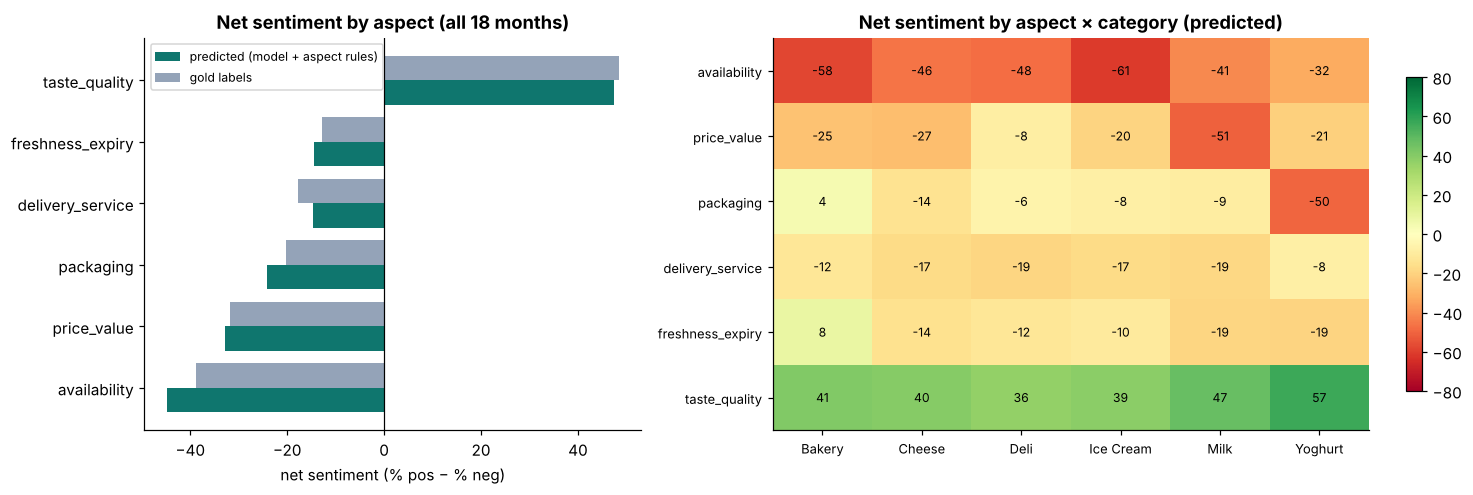

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
s = aspect_summary.sort_values("net sentiment (predicted)")
y = np.arange(len(s))
ax[0].barh(y - .2, s["net sentiment (predicted)"], .4, color=TEAL, label="predicted (model + aspect rules)")
ax[0].barh(y + .2, s["net sentiment (gold)"], .4, color=GREY, label="gold labels")
ax[0].set_yticks(y, s.index); ax[0].axvline(0, color="k", lw=.8)
ax[0].set_xlabel("net sentiment (% pos − % neg)"); ax[0].set_title("Net sentiment by aspect (all 18 months)"); ax[0].legend(fontsize=8)
hm = asp.pivot_table(index="aspect", columns="category", values="aspect_sentiment", aggfunc=net).loc[s.index]
im = ax[1].imshow(hm.values, cmap="RdYlGn", vmin=-80, vmax=80, aspect="auto")
ax[1].set_xticks(range(hm.shape[1]), hm.columns, fontsize=8.5); ax[1].set_yticks(range(hm.shape[0]), hm.index, fontsize=8.5)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax[1].text(j, i, f"{hm.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Net sentiment by aspect × category (predicted)"); plt.colorbar(im, ax=ax[1], shrink=.8)
plt.tight_layout(); plt.savefig(OUT / "07_aspect_sentiment.png", dpi=130, bbox_inches="tight"); plt.show()

**Interpretation**

* **Aspect detection works well on this data:** F1 ranges from 0.885 (taste) to 0.988 (freshness). **Taste has the lowest recall (0.83)** because generic praise such as "safi kabisa" or "hii mala ni noma" contains no taste keyword. **Delivery (precision 0.84) and packaging (0.86) produce the most false alarms**, because words like "order" and "packet" also appear in other contexts. *Caveat:* the keyword rules were written knowing the generator's vocabulary, so these detection scores are an **upper bound** for real data.
* **Sentiment per aspect needs the ML model.** Applying the Linear SVM to the clause gives the correct aspect polarity 97.5% of the time, against 77.3% for the extended lexicon. The lexicon is especially poor on **availability (0.65)** and **delivery (0.59)**: "customers keep asking and we have none" and "waited the whole day for the van" contain no sentiment word, yet they are clearly complaints.
* **The business picture is clear: customers love the product but are frustrated by the operation around it.**
  * **Taste/quality is the brand's strength: net +47.5** (gold +48.4), positive in every category and highest for Yoghurt (+57).
  * **Availability is the biggest problem: net −44.8** (gold −38.8), worst for Ice Cream (−61) and Bakery (−58).
  * **Price comes next (−32.8)**, concentrated on **Milk (−51)**, which reflects the January price increase.
  * **Packaging (−24.1)** is a **Yoghurt-specific** problem (−50 for yoghurt vs. single digits elsewhere): the new cup.
  * Delivery/service (−14.6) and freshness (−14.5) are moderately negative.
* **Predicted net scores are within 6 points of the gold scores** for every aspect. The order matches, apart from freshness and delivery, which are practically tied in the predictions (−14.5 vs −14.6) while gold puts delivery lower (−17.7 vs −12.9). That is accurate enough for prioritising.

---
## 15. Topic discovery on negative feedback (NMF)

Aspect rules only find what we told them to look for. **Topic modelling** finds recurring themes nobody listed in advance. We use **Non-negative Matrix Factorisation (NMF)** on the TF-IDF matrix of all feedback the model predicts as **negative**:

$$X_{\text{docs} \times \text{words}} \approx W_{\text{docs} \times k} \cdot H_{k \times \text{words}}$$

* Each row of **H** is a *topic*: a weighted list of words that tend to appear together.
* Each row of **W** says how much each topic is present in each document.
* Because everything is non-negative, topics are *additive* and easy to read, which suits short texts better than LDA does.

Preparation matters more than the algorithm here:

* **Channel boilerplate is removed first** (`strip_boilerplate`): greetings ("Hello customer care,"), agent prefixes ("Caller says:"), sign-offs ("Please sort this out", "Asante sana"), hashtags and batch numbers. These phrases are frequent, so left in they *become* the topics ("hello customer care") without saying anything about the problem.
* Stop-words (English and Kiswahili, **keeping negations**) and intensifiers ("totally", "super") are removed, and the Swahili/Sheng-normalised text is used, so "inavuja" and "leaking" count as the same word.
* **Product names are masked.** Otherwise the most frequent product words ("yoghurt", "milk") pull unrelated complaints into one topic per product. We want topics about *problems*; the product comes back from the metadata (the "main category" column). We fit **k = 10 topics**. The reconstruction error for k = 4–12 falls smoothly with no clear elbow (printed below), so k is chosen for **interpretability**: we tried 8, 9 and 10, and at 10 the topics stop merging distinct problems (leaking lids vs. spoiled yoghurt) while staying few enough for a business reader. Topic names are assigned by simple keyword rules on each topic's top terms, so they stay stable when the notebook is re-run.

In [27]:
pred_all = pd.Series(index=df.index, dtype=object)
oof = cross_val_predict(best_est[BEST], train.clean, train.sentiment, cv=cv, n_jobs=-1)  # out-of-fold for the training period
pred_all.loc[train.index] = oof
pred_all.loc[test.index] = test[f"pred_{BEST}"]
df["pred"] = pred_all
print(f"Predicted labels for all {len(df):,} items (out-of-fold for train, true out-of-sample for test). "
      f"Agreement with gold: {(df.pred == df.sentiment).mean():.1%}")
neg = df[df.pred == "negative"].copy()
topic_text = neg.text.map(lambda t: tu.clean_text(tu.CATALOGUE_RE.sub(" ", tu.strip_boilerplate(t)), normalise_sw=True)) \
                    .str.replace(r"\bemj_\w+|\bbrandtoken\b|\bbatchno\b|\bmention\b", " ", regex=True)
print("Example after boilerplate removal:", neg.text.iloc[0], "->", topic_text.iloc[0])
tv = TfidfVectorizer(ngram_range=(1, 2), min_df=8, max_df=.4, stop_words=list(tu.STOPWORDS | tu.INTENSIFIERS), sublinear_tf=True)
Xn = tv.fit_transform(topic_text)
errs = {k: NMF(k, init="nndsvda", random_state=SEED, max_iter=600).fit(Xn).reconstruction_err_ for k in range(4, 13)}
print("NMF reconstruction error by k:", {k: round(v, 1) for k, v in errs.items()})
K = 10
nmf = NMF(K, init="nndsvda", random_state=SEED, max_iter=600)
W = nmf.fit_transform(Xn); H = nmf.components_
terms = np.array(tv.get_feature_names_out())
neg["topic"] = W.argmax(1); neg["topic_weight"] = W.max(1)
topics = pd.DataFrame({"top terms": [", ".join(terms[np.argsort(h)[::-1][:9]]) for h in H],
                       "docs": neg.topic.value_counts().reindex(range(K)).values,
                       "main category": [neg[neg.topic == k].category.value_counts().idxmax() for k in range(K)],
                       "peak month": [str(neg[neg.topic == k].month.value_counts().idxmax()) for k in range(K)]})
topics

Predicted labels for all 8,298 items (out-of-fold for train, true out-of-sample for test). Agreement with gold: 90.2%


Example after boilerplate removal: Habari, order ilikuja nusu and the 2L ice cream tub was full of ice crystals Kindly call back. 😤 -> order incomplete and the was full of ice crystals  


NMF reconstruction error by k: {4: np.float64(58.8), 5: np.float64(58.2), 6: np.float64(57.7), 7: np.float64(57.1), 8: np.float64(56.6), 9: np.float64(56.0), 10: np.float64(55.5), 11: np.float64(55.0), 12: np.float64(54.5)}


,top terms,docs,main category,peak month
0,"stock, stock everywhere, weeks, stock weeks, everywhere, not, not received, received, received stock",625,Milk,2025-12
1,"price, hike, price hike, pack, pack smaller, smaller price, smaller, off price, rip off",393,Milk,2026-01
2,"late, delivery, delivery late, curdled, boiled, curdled boiled, overpriced, expiry, delivery failed",255,Milk,2026-01
3,"gone, bad, gone bad, price gone, smells bad, smells, fridge, fridge off, shop fridge",302,Milk,2026-06
4,"expensive, sold, not, order, smells bad, smells, bad, unavailable, fridge",184,Milk,2025-12
5,"lid, leaks, lid leaks, mould lid, mould, new, cup, leaking, new cup",889,Yoghurt,2025-10
6,"customers keep, customers, asking none, keep asking, asking, none, keep, fresh, order",147,Milk,2025-12
7,"off, smelt, smelt off, separated smelt, separated, off price, rip, rip off, sour opening",249,Yoghurt,2026-06
8,"care, customer care, customer, ages, hold, keeps, keeps hold, hold ages, care keeps",392,Milk,2026-06
9,"packet, burst bag, burst, packet burst, bag, packet leaking, leaking, expiry, expiry date",382,Milk,2026-06


In [28]:
for k in range(K):
    ex = neg[neg.topic == k].nlargest(3, "topic_weight").text.tolist()
    print(f"Topic {k}: {ex}")

Topic 0: ['From the duka owner: We have not received stock for two weeks.', 'From the duka owner: We have not received stock for two weeks!!!', 'Hello maziwa bora, we have not received stock for two weeks 💔']
Topic 1: ['Review: The price went up again.', 'Mimi nasema the price went up again. Fix this! 😠😞', 'Hi, the price went up again. Never again. 👎']
Topic 2: ['Habari, delivery was late again.', 'Customer reports: Delivery was late again Fix this!', 'Delivery imechelewa tena. Please sort this out. 🤮💔']
Topic 3: ['Habari, the 500ml milk packet had gone bad Never again.', 'The cheddar had gone bad Please sort this out.', 'Aki, the mozzarella had gone bad Very disappointed. 😠']
Topic 4: ['Totally expensive Very disappointed.', 'Manze, so expensive.', 'Review: Ni ghali sana siku hizi. 🤮😡']
Topic 5: ['Good morning, mould on the lid of the strawberry yoghurt, also the lid leaks. Kindly call back.', 'Hello customer care, the lid leaks. 👎', 'Honestly the lid leaks.']
Topic 6: ['Customers kee

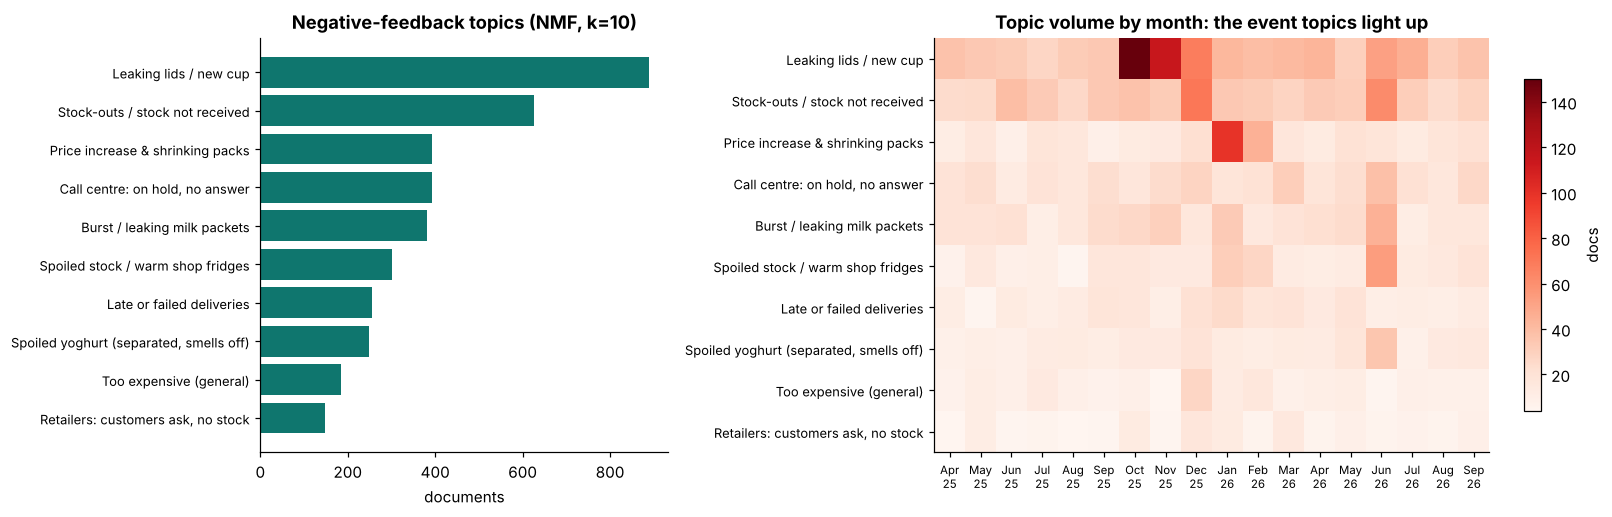

In [29]:
NAME_RULES = [  # (any of these in the top-8 terms -> name); order matters
    (["lid", "cup", "lid leaks"], "Leaking lids / new cup"),
    (["burst", "packet leaking", "burst bag"], "Burst / leaking milk packets"),
    (["hike", "smaller", "pack smaller"], "Price increase & shrinking packs"),
    (["customers keep", "asking none"], "Retailers: customers ask, no stock"),
    (["stock", "stock everywhere"], "Stock-outs / stock not received"),
    (["customer care", "hold ages"], "Call centre: on hold, no answer"),
    (["smelt off", "separated"], "Spoiled yoghurt (separated, smells off)"),
    (["gone bad", "fridge", "shop fridge"], "Spoiled stock / warm shop fridges"),
    (["late", "delivery late", "delivery failed"], "Late or failed deliveries"),
    (["curdled", "expiry"], "Milk curdling before expiry"),
    (["expensive"], "Too expensive (general)"),
]
TOPIC_NAMES = {}
for k in range(K):
    top = list(terms[np.argsort(H[k])[::-1][:8]])
    name = next((n for keys, n in NAME_RULES if any(t in top for t in keys) and n not in TOPIC_NAMES.values()),
                "Mixed: " + ", ".join(top[:3]))
    TOPIC_NAMES[k] = name
TOPIC_NAMES
topics.insert(0, "topic name", [TOPIC_NAMES[k] for k in range(K)])
topics.to_csv(OUT / "negative_topics_nmf.csv")
neg["topic_name"] = neg.topic.map(TOPIC_NAMES)
tm = pd.crosstab(neg.month, neg.topic_name)
tm.index = tm.index.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
sz = neg.topic_name.value_counts().sort_values()
ax[0].barh(sz.index, sz.values, color=TEAL); ax[0].set_title("Negative-feedback topics (NMF, k=10)"); ax[0].set_xlabel("documents")
ax[0].tick_params(axis="y", labelsize=8.5)
im = ax[1].imshow(tm[sz.index[::-1]].T.values, aspect="auto", cmap="Reds")
ax[1].set_yticks(range(len(sz)), sz.index[::-1], fontsize=8.5)
ax[1].set_xticks(range(len(tm)), [d.strftime("%b\n%y") for d in tm.index], fontsize=7.5)
ax[1].set_title("Topic volume by month: the event topics light up"); plt.colorbar(im, ax=ax[1], shrink=.8, label="docs")
plt.tight_layout(); plt.savefig(OUT / "08_negative_topics.png", dpi=130, bbox_inches="tight"); plt.show()

**Interpretation**

NMF found ten readable complaint themes in the negative feedback, without being given any categories:

| Topic | Docs | Peak month | What it is |
|---|---:|---|---|
| Leaking lids / new cup | 889 | **Oct 2025** | The new yoghurt cup (event E1); the largest single theme |
| Stock-outs / stock not received | 625 | **Dec 2025** | Empty shelves; peaks with the festive ice-cream stock-out (E2) |
| Price increase & shrinking packs | 393 | **Jan 2026** | The milk price increase (E3), plus "the pack got smaller" complaints |
| Call centre: on hold, no answer | 392 | Jun 2026 | Service failure; rises when complaint volume surges |
| Burst / leaking milk packets | 382 | Jun 2026 | Packet integrity, a different problem from the yoghurt cup |
| Spoiled stock / warm shop fridges | 302 | **Jun 2026** | The Coast cold-chain incident (E5): "the shop fridge was off" |
| Late or failed deliveries | 255 | Jan 2026 | Route and delivery reliability (mixed with some curdling complaints) |
| Spoiled yoghurt (separated, smells off) | 249 | **Jun 2026** | Also part of the E5 incident |
| Too expensive (general) | 184 | Dec 2025 | A catch-all for short price complaints |
| Retailers: customers ask, no stock | 147 | Dec 2025 | The retailer's view of stock-outs |

* **Three negative events stand out clearly in the monthly heatmap**: leaking lids in Oct–Nov 2025, price in Jan 2026, and the June 2026 cold-chain incident, which lights up several freshness topics at once. The December stock-out shows up in two topics. The positive launch (E4) does not appear, because only negative feedback was modelled.
* **A June knock-on effect:** call-centre and burst-packet complaints also peak in June 2026. When an incident drives up contact volume, service failures follow. That is worth knowing when staffing the call centre.
* **Limits:** two topics are mixed ("late deliveries" picks up some curdling terms; "too expensive" is a catch-all). "Milk" as the main category is mostly a base-rate effect, because milk is the largest category. Topic models are **exploratory**: they suggest themes for a person to name and confirm. They are not a precise classifier.

---
## 16. Trend analysis and anomaly detection: would we have caught the problems in time?

We now treat sentiment as a **monthly KPI** and look for months that break the pattern. For each segment (category, region, and category × region) and each month we compute:

$$\text{net sentiment}_t = \frac{\#\text{positive}_t - \#\text{negative}_t}{n_t} \in [-1, +1]$$

and a **rolling z-score** against the segment's own recent history:

$$z_t = \frac{\text{net}_t - \text{median}(\text{net}_{t-6..t-1})}{\sqrt{\hat\sigma^2 / n_t}}$$

* The **baseline** is the median of the previous six months (at least three). The median is used because a previous spike should not distort the next month's baseline.
* The **denominator is the sampling standard error**: $\hat\sigma^2$ is the pooled item-level variance of the score (−1/0/+1) over the baseline months. A small region with 25 items a month moves more by chance than Nairobi with 300, and this takes that into account. A plain z-score on six monthly values would have only six points to estimate the spread from, and would raise false alarms.
* **Alert rule:** |z| ≥ 3.5 **and** the shift is at least 0.20 net-sentiment points **and** n ≥ 20. Both a statistical and a business-size threshold must be met, which keeps false alarms down.

This runs on the **model's predicted labels**, as it would in production, where nobody hand-labels new feedback. We check it against the gold labels afterwards.

In [30]:
SCORE = {"positive": 1, "neutral": 0, "negative": -1}
df["s_pred"] = df.pred.map(SCORE); df["s_gold"] = df.sentiment.map(SCORE)
df["category_region"] = df.category + " | " + df.region
MONTHS = pd.period_range(df.month.min(), df.month.max(), freq="M")
Z_MIN, DELTA_MIN, N_MIN, WINDOW = 3.5, 0.20, 20, 6

def scan(dim, score_col):
    out = []
    for seg, g in df.groupby(dim):
        m = g.groupby("month")[score_col].agg(n="size", net="mean", sq=lambda x: (x ** 2).mean()).reindex(MONTHS)
        for i, mon in enumerate(MONTHS):
            if pd.isna(m.net.iloc[i]) or m.n.iloc[i] < N_MIN:
                continue
            b = m.iloc[max(0, i - WINDOW):i].dropna()
            if len(b) < 3:
                continue
            base = b.net.median()
            var = np.average(b.sq, weights=b.n) - np.average(b.net, weights=b.n) ** 2
            z = (m.net.iloc[i] - base) / np.sqrt(var / m.n.iloc[i])
            if abs(z) >= Z_MIN and abs(m.net.iloc[i] - base) >= DELTA_MIN:
                out.append({"dimension": dim, "segment": seg, "month": str(mon), "items": int(m.n.iloc[i]),
                            "net_sentiment": round(m.net.iloc[i], 2), "baseline": round(base, 2), "z": round(z, 1),
                            "direction": "positive spike" if z > 0 else "negative spike"})
    return out

anoms = pd.DataFrame([a for dim in ["category", "region", "category_region"] for a in scan(dim, "s_pred")])
anoms_gold = pd.DataFrame([a for dim in ["category", "region", "category_region"] for a in scan(dim, "s_gold")])
key = lambda d: set(zip(d.dimension, d.segment, d.month))
print(f"Alerts on PREDICTED labels: {len(anoms)} | on GOLD labels: {len(anoms_gold)} | "
      f"in both: {len(key(anoms) & key(anoms_gold))}")
anoms.sort_values(["month", "dimension"])

Alerts on PREDICTED labels: 27 | on GOLD labels: 20 | in both: 19


,dimension,segment,month,items,net_sentiment,baseline,z,direction
4,category,Yoghurt,2025-10,275,-0.44,-0.01,-7.6,negative spike
25,category_region,Yoghurt | Rift Valley,2025-10,46,-0.54,0.00,-4.0,negative spike
5,category,Yoghurt,2025-11,214,-0.33,-0.07,-4.2,negative spike
0,category,Ice Cream,2025-12,144,-0.64,0.11,-9.9,negative spike
15,category_region,Ice Cream | Nairobi,2025-12,121,-0.78,0.03,-9.6,negative spike
1,category,Milk,2026-01,278,-0.49,0.02,-9.1,negative spike
17,category_region,Milk | Nairobi,2026-01,80,-0.54,-0.01,-5.1,negative spike
18,category_region,Milk | Rift Valley,2026-01,45,-0.40,0.17,-4.2,negative spike
19,category_region,Milk | Western,2026-01,25,-0.92,0.20,-6.1,negative spike
13,region,Western,2026-01,49,-0.53,0.12,-4.8,negative spike


In [31]:
# Which aspect drove each alert? Compare each aspect's negative (or positive) share with the segment's baseline months.
def driver(row):
    dim_col = row.dimension
    seg_ids = df.loc[(df[dim_col] == row.segment), "feedback_id"]
    a = asp[asp.feedback_id.isin(seg_ids)]
    mon = pd.Period(row.month, "M")
    cur = a[a.month == mon]; base = a[(a.month < mon) & (a.month >= mon - WINDOW)]
    target = "negative" if row.direction == "negative spike" else "positive"
    lift = {}  # extra mentions this month vs the average baseline month
    for asp_name in ASPECTS:
        c = (cur.aspect.eq(asp_name) & cur.aspect_sentiment.eq(target)).sum()
        bb = (base.aspect.eq(asp_name) & base.aspect_sentiment.eq(target)).sum() / max(base.month.nunique(), 1)
        lift[asp_name] = c - bb
    top = max(lift, key=lift.get)
    return pd.Series({"driver_aspect": top, "extra_mentions_vs_baseline": round(lift[top], 1)})
anoms = anoms.join(anoms.apply(driver, axis=1))
# A positive spike that only brings a segment back to its long-run level is a RECOVERY after an earlier problem
# (the trailing baseline is still depressed by that problem), not new good news.
long_run = {(dim, seg): g["s_pred"].mean() for dim in ["category", "region", "category_region"] for seg, g in df.groupby(dim)}
is_recovery = (anoms.direction == "positive spike") & (
    anoms.apply(lambda r: r.net_sentiment <= long_run[(r.dimension, r.segment)] + 0.10, axis=1))
anoms.loc[is_recovery, "direction"] = "recovery"
print(f"{is_recovery.sum()} positive spike(s) reclassified as recovery to the long-run level")

# Group alerts into EPISODES (same driver aspect, overlapping segments, consecutive months) for the summary
anoms["episode"] = anoms.apply(lambda r: f"{r.driver_aspect} / {r.direction}", axis=1)
episodes = (anoms.groupby("episode")
            .agg(months=("month", lambda s: ", ".join(sorted(set(s)))), alerts=("segment", "size"),
                 segments=("segment", lambda s: "; ".join(sorted(set(s)))[:150]), min_z=("z", lambda s: s.abs().max()))
            .sort_values("months"))
episodes

0 positive spike(s) reclassified as recovery to the long-run level


,months,alerts,segments,min_z
episode,,,,
packaging / negative spike,"2025-10, 2025-11",3,Yoghurt; Yoghurt | Rift Valley,7.6
availability / negative spike,2025-12,2,Ice Cream; Ice Cream | Nairobi,9.9
price_value / negative spike,"2026-01, 2026-02",6,Milk; Milk | Nairobi; Milk | Rift Valley; Milk | Western; Western,9.1
taste_quality / positive spike,"2026-03, 2026-04",10,Nairobi; Rift Valley; Western; Yoghurt; Yoghurt | Central; Yoghurt | Coast; Yoghurt | Nairobi; Yoghurt | Rift Valley,8.5
price_value / positive spike,2026-04,1,Nairobi,4.3
freshness_expiry / negative spike,2026-06,5,Coast; Milk; Milk | Coast; Yoghurt; Yoghurt | Coast,9.6


In [32]:
# Ground truth: the five events the generator embedded (documented in data/generate_data.py)
TRUTH = pd.DataFrame([
    ("E1", "Yoghurt new cup / lid leaks", "2025-10, 2025-11", "Yoghurt", "all", "packaging", "negative"),
    ("E2", "Festive ice-cream stock-out", "2025-12", "Ice Cream", "Nairobi", "availability", "negative"),
    ("E3", "Milk price increase", "2026-01, 2026-02", "Milk", "all", "price_value", "negative"),
    ("E4", "Baobab Honey flavour launch", "2026-03, 2026-04", "Yoghurt", "all", "taste_quality", "positive"),
    ("E5", "Coast cold-chain / expiry incident", "2026-06", "Milk & Yoghurt", "Coast", "freshness_expiry", "negative"),
], columns=["event", "what happened", "months", "category", "region", "aspect", "polarity"])
def found(ev):
    hits = anoms[(anoms.driver_aspect == ev.aspect) & (anoms.direction.str.startswith(ev.polarity)) &
                 anoms.month.isin([m.strip() for m in ev.months.split(",")])]
    return pd.Series({"detected?": "yes" if len(hits) else "NO", "alerts": len(hits),
                      "first alert": hits.month.min() if len(hits) else "-",
                      "strongest |z|": hits.z.abs().max() if len(hits) else np.nan,
                      "alerted segments": "; ".join(sorted(set(hits.segment)))[:110]})
truth_check = TRUTH.join(TRUTH.apply(found, axis=1))
matched = set()
for ev in TRUTH.itertuples():
    m = anoms[(anoms.driver_aspect == ev.aspect) & (anoms.direction.str.startswith(ev.polarity)) &
              anoms.month.isin([x.strip() for x in ev.months.split(",")])]
    matched |= set(m.index)
unexplained = anoms.drop(index=list(matched))
print(f"{(truth_check['detected?'] == 'yes').sum()} of {len(TRUTH)} embedded events detected | "
      f"{len(unexplained)} of {len(anoms)} alerts not explained by an embedded event")
truth_check

5 of 5 embedded events detected | 1 of 27 alerts not explained by an embedded event


,event,what happened,months,category,region,aspect,polarity,detected?,alerts,first alert,strongest |z|,alerted segments
0,E1,Yoghurt new cup / lid leaks,"2025-10, 2025-11",Yoghurt,all,packaging,negative,yes,3,2025-10,7.6,Yoghurt; Yoghurt | Rift Valley
1,E2,Festive ice-cream stock-out,2025-12,Ice Cream,Nairobi,availability,negative,yes,2,2025-12,9.9,Ice Cream; Ice Cream | Nairobi
2,E3,Milk price increase,"2026-01, 2026-02",Milk,all,price_value,negative,yes,6,2026-01,9.1,Milk; Milk | Nairobi; Milk | Rift Valley; Milk | Western; Western
3,E4,Baobab Honey flavour launch,"2026-03, 2026-04",Yoghurt,all,taste_quality,positive,yes,10,2026-03,8.5,Nairobi; Rift Valley; Western; Yoghurt; Yoghurt | Central; Yoghurt | Coast; Yoghurt | Nairobi; Yoghurt | Rift
4,E5,Coast cold-chain / expiry incident,2026-06,Milk & Yoghurt,Coast,freshness_expiry,negative,yes,5,2026-06,9.6,Coast; Milk; Milk | Coast; Yoghurt; Yoghurt | Coast


In [33]:
# Cross-check: does the same scan on the GOLD labels find the same events? (event months x event segments)
ev_hits = {}
for ev in TRUTH.itertuples():
    months = [x.strip() for x in ev.months.split(",")]
    cats = ["Milk", "Yoghurt"] if ev.category == "Milk & Yoghurt" else [ev.category]
    seg_ok = anoms_gold.segment.apply(lambda sgm: any(c in sgm for c in cats) or (ev.region != "all" and ev.region in sgm))
    ev_hits[ev.event] = int((anoms_gold.month.isin(months) & seg_ok).sum())
print("Gold-label alerts in each event's months and segments:", ev_hits)
unexplained[["dimension", "segment", "month", "items", "net_sentiment", "baseline", "z", "driver_aspect"]]

Gold-label alerts in each event's months and segments: {'E1': 2, 'E2': 2, 'E3': 5, 'E4': 5, 'E5': 5}


,dimension,segment,month,items,net_sentiment,baseline,z,driver_aspect
11,region,Nairobi,2026-04,167,0.14,-0.17,4.3,price_value


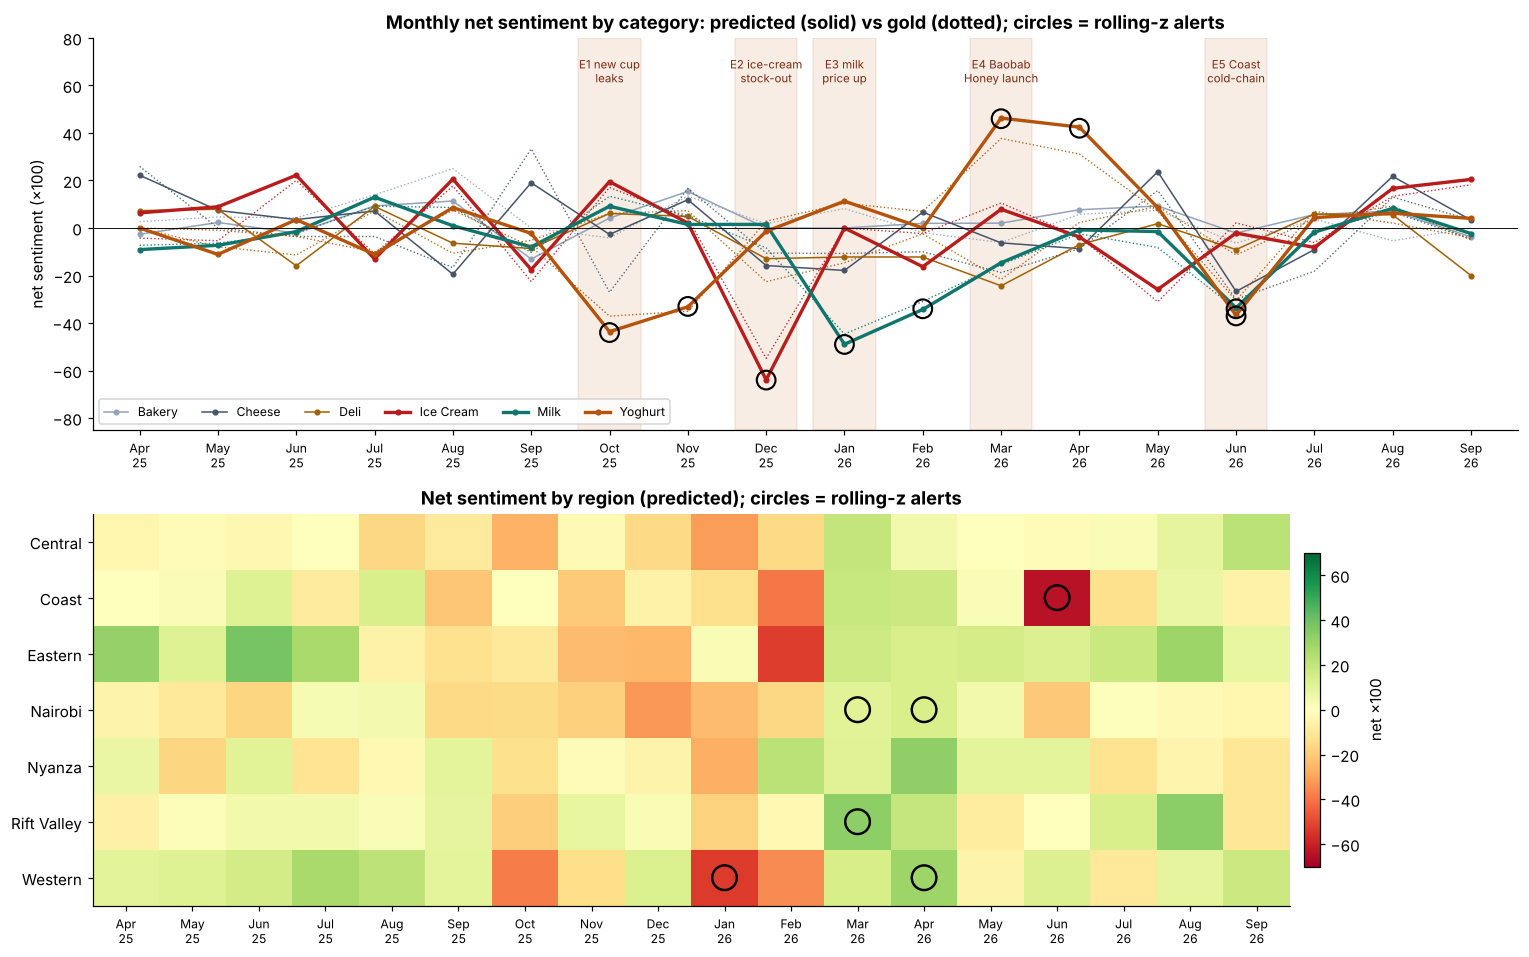

In [34]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8.8))
xi = {m: i for i, m in enumerate(MONTHS)}
xt = [m.strftime("%b\n%y") for m in MONTHS]
cat_m = df.groupby(["month", "category"]).agg(pred=("s_pred", "mean"), gold=("s_gold", "mean")).reset_index()
cat_m["x"] = cat_m.month.map(xi)
cols = {"Milk": TEAL, "Yoghurt": AMBER, "Ice Cream": RED, "Cheese": "#475569", "Bakery": GREY, "Deli": "#a16207"}
for c, g in cat_m.groupby("category"):
    lw = 2.2 if c in ("Milk", "Yoghurt", "Ice Cream") else 1
    ax[0].plot(g.x, g.pred * 100, color=cols[c], lw=lw, label=c, marker="o", ms=3)
    ax[0].plot(g.x, g.gold * 100, color=cols[c], lw=.9, ls=":", alpha=.9)
ev_lbl = [("2025-10", "E1 new cup\nleaks"), ("2025-12", "E2 ice-cream\nstock-out"), ("2026-01", "E3 milk\nprice up"),
          ("2026-03", "E4 Baobab\nHoney launch"), ("2026-06", "E5 Coast\ncold-chain")]
for m, l in ev_lbl:
    i = xi[pd.Period(m, "M")]
    ax[0].axvspan(i - .4, i + .4, color=AMBER, alpha=.10)
    ax[0].text(i, 66, l, fontsize=7.5, ha="center", va="center", color="#7c2d12")
cat_alerts = anoms[anoms.dimension == "category"]
for r in cat_alerts.itertuples():
    ax[0].scatter(xi[pd.Period(r.month, "M")], r.net_sentiment * 100, s=150, facecolors="none", edgecolors="k", lw=1.4, zorder=5)
ax[0].axhline(0, color="k", lw=.6); ax[0].set_ylim(-85, 80); ax[0].set_xlim(-.6, len(MONTHS) - .4)
ax[0].set_xticks(range(len(MONTHS)), xt, fontsize=8)
ax[0].set_ylabel("net sentiment (×100)"); ax[0].legend(ncol=6, fontsize=8, loc="lower left")
ax[0].set_title("Monthly net sentiment by category: predicted (solid) vs gold (dotted); circles = rolling-z alerts")
reg_m = df.groupby(["month", "region"]).s_pred.mean().unstack().reindex(MONTHS)
im = ax[1].imshow(reg_m.T.values * 100, aspect="auto", cmap="RdYlGn", vmin=-70, vmax=70)
ax[1].set_yticks(range(len(reg_m.columns)), reg_m.columns)
ax[1].set_xticks(range(len(MONTHS)), xt, fontsize=8)
for r in anoms[anoms.dimension == "region"].itertuples():
    ax[1].scatter(xi[pd.Period(r.month, "M")], list(reg_m.columns).index(r.segment), s=260, facecolors="none",
                  edgecolors="k", lw=1.6)
ax[1].set_title("Net sentiment by region (predicted); circles = rolling-z alerts")
plt.colorbar(im, ax=ax[1], shrink=.8, pad=.01, label="net ×100")
plt.tight_layout(); plt.savefig(OUT / "09_trends_and_alerts.png", dpi=130, bbox_inches="tight"); plt.show()

In [35]:
monthly = (df.groupby(["month", "category", "region"])
           .agg(items=("feedback_id", "size"), net_pred=("s_pred", "mean"), net_gold=("s_gold", "mean"),
                pct_negative_pred=("pred", lambda s: (s == "negative").mean()))
           .round(3).reset_index())
monthly.to_csv(OUT / "monthly_sentiment.csv", index=False)
cat_corr = cat_m.groupby("category").apply(lambda g: np.corrcoef(g.pred, g.gold)[0, 1]).round(3)
print("Correlation between predicted and gold monthly net sentiment, by category:", cat_corr.to_dict())

Correlation between predicted and gold monthly net sentiment, by category: {'Bakery': 0.544, 'Cheese': 0.846, 'Deli': 0.745, 'Ice Cream': 0.954, 'Milk': 0.966, 'Yoghurt': 0.972}


**Interpretation**

* **All five embedded events were detected, each in the month it started**, without the scan being told where to look:

| Event | First alert | Strongest \|z\| | Where it showed up |
|---|---|---:|---|
| E1 Yoghurt new-cup leaks | Oct 2025 | 7.6 | Yoghurt (Oct and Nov), Yoghurt in Rift Valley |
| E2 Festive ice-cream stock-out | Dec 2025 | 9.9 | Ice Cream; Ice Cream in Nairobi |
| E3 Milk price increase | Jan 2026 | 9.1 | Milk (Jan and Feb); Milk in Nairobi, Rift Valley and Western; Western region overall |
| E4 Baobab Honey launch (positive) | Mar 2026 | 8.5 | Yoghurt (Mar and Apr) and Yoghurt in four regions |
| E5 Coast cold-chain incident | Jun 2026 | 9.6 | Coast region; Milk and Yoghurt in Coast; Milk and Yoghurt nationally |

* **26 of the 27 alerts belong to an embedded event.** Because each event shows up at several levels (category, region, category × region), one event produces several alerts. The episode table groups them back into **six episodes**. The **one unexplained alert** is a low-severity positive spike for **Nairobi in April 2026** (z = 4.3). Nairobi's baseline was still depressed by the December stock-out and the January price complaints, and April also carried the Baobab Honey launch, so this is a rebound mixed with the launch rather than a new event. The "recovery" rule (positive spike that only returns a segment to within 0.10 of its long-run level) did not reclassify it, because April was above Nairobi's long-run level. It is exactly the kind of alert an analyst would glance at and close.
* **The drill-down levels matter.** The December ice-cream stock-out is very strong for *Ice Cream in Nairobi* (z = −9.6) but diluted in Nairobi's overall score, where it did not trigger an alert. The price increase was felt most in **Western** (Milk net sentiment −0.92 in January, from a baseline of +0.20).
* **Predicted labels are good enough to run the monitor.** The scan on predicted labels raised 27 alerts and the same scan on gold labels raised 20. 19 are in both, and every embedded event is found either way. The model's few extra alerts are additional segments of the same events. Predicted and gold monthly net sentiment correlate at 0.97 for Yoghurt and Milk and 0.95 for Ice Cream, but only 0.54 for Bakery and 0.75 for Deli. Small categories have few items per month, so their monthly scores are noisier.
* **Small segments are a blind spot.** Eastern region shows a sharp dip in February 2026 on the heatmap, but with fewer than 20 items that month it is below the minimum volume for an alert. A weekly roll-up or pooling small regions would be the fix.

## 17. From insight to action: the alert file

A dashboard that nobody looks at catches nothing. The last step turns each anomaly into a **routed alert**: what happened, how unusual it is, what drove it, **who owns it** and **three example messages**, so the owner can see the problem in the customers' own words.

In [36]:
OWNERS = {
    "taste_quality": ("Quality Assurance / R&D", "Check recent batches and recipe changes; run a taste panel"),
    "freshness_expiry": ("Cold-chain & QA", "Audit cold chain and outlet fridges in the region; pull and trace affected batches"),
    "price_value": ("Commercial / Pricing", "Review price-pack architecture; consider a value pack or promotion"),
    "packaging": ("Packaging engineering & Procurement", "Test seal integrity of the new pack; escalate to supplier"),
    "availability": ("Supply planning & Sales ops", "Re-plan allocation and replenishment; check distributor fill rates"),
    "delivery_service": ("Distribution & Customer service", "Review route adherence and call-centre service levels"),
}
def examples(r):
    ids = df.loc[(df[r.dimension] == r.segment) & (df.month == pd.Period(r.month, "M")), "feedback_id"]
    target = "negative" if r.direction == "negative spike" else "positive"
    a = asp[asp.feedback_id.isin(ids) & (asp.aspect == r.driver_aspect) & (asp.aspect_sentiment == target)]
    txt = df.set_index("feedback_id").loc[a.feedback_id.unique()[:3], "text"].tolist()
    return " || ".join(txt)
alerts = anoms.copy()
alerts["severity"] = np.select([alerts.direction == "recovery", alerts.z.abs() >= 8, alerts.z.abs() >= 5], ["info", "high", "medium"], "low")
def route(a, d):
    if d == "positive spike":
        return "Marketing (amplify the win)", "Amplify: share reviews, secure distribution and stock for demand"
    if d == "recovery":
        return "Analytics (monitor)", "Confirm the earlier issue is closed; no new action"
    return OWNERS[a]
alerts["owner"] = [route(a, d)[0] for a, d in zip(alerts.driver_aspect, alerts.direction)]
alerts["suggested_action"] = [route(a, d)[1] for a, d in zip(alerts.driver_aspect, alerts.direction)]
alerts["example_feedback"] = alerts.apply(examples, axis=1)
alerts = alerts.assign(abs_z=alerts.z.abs()).sort_values(["month", "abs_z"], ascending=[True, False]).drop(columns=["episode", "abs_z"])
alerts.to_csv(OUT / "alerts.csv", index=False)
print(f"Saved outputs/alerts.csv with {len(alerts)} alerts")
alerts[["month", "dimension", "segment", "net_sentiment", "baseline", "z", "severity", "driver_aspect", "owner"]]

Saved outputs/alerts.csv with 27 alerts


,month,dimension,segment,net_sentiment,baseline,z,severity,driver_aspect,owner
4,2025-10,category,Yoghurt,-0.44,-0.01,-7.6,medium,packaging,Packaging engineering & Procurement
25,2025-10,category_region,Yoghurt | Rift Valley,-0.54,0.00,-4.0,low,packaging,Packaging engineering & Procurement
5,2025-11,category,Yoghurt,-0.33,-0.07,-4.2,low,packaging,Packaging engineering & Procurement
0,2025-12,category,Ice Cream,-0.64,0.11,-9.9,high,availability,Supply planning & Sales ops
15,2025-12,category_region,Ice Cream | Nairobi,-0.78,0.03,-9.6,high,availability,Supply planning & Sales ops
1,2026-01,category,Milk,-0.49,0.02,-9.1,high,price_value,Commercial / Pricing
19,2026-01,category_region,Milk | Western,-0.92,0.20,-6.1,medium,price_value,Commercial / Pricing
17,2026-01,category_region,Milk | Nairobi,-0.54,-0.01,-5.1,medium,price_value,Commercial / Pricing
13,2026-01,region,Western,-0.53,0.12,-4.8,low,price_value,Commercial / Pricing
18,2026-01,category_region,Milk | Rift Valley,-0.40,0.17,-4.2,low,price_value,Commercial / Pricing


In [37]:
# Note: Logistic Regression is saved for deployment, not the (statistically tied) Linear SVM, because it gives
# calibrated probabilities (useful for thresholds and alert confidence) and directly interpretable weights.
scored = df[["feedback_id", "date", "channel", "category", "product", "region", "text", "sentiment", "pred"]].rename(
    columns={"sentiment": "gold_sentiment", "pred": "predicted_sentiment"})
scored["detected_aspects"] = df.aspects_found.map(lambda d: "|".join(d))
scored.to_csv(OUT / "scored_feedback.csv", index=False)

# Save the production pipeline (cleaning + features + model) if it is small enough to keep in the repo
import joblib, os
tmp = OUT / "sentiment_model.joblib"
try:
    joblib.dump(best_est["Logistic Regression"], tmp, compress=3)
    size_mb = os.path.getsize(tmp) / 1e6
    if size_mb > 5:
        tmp.unlink(); print(f"Model is {size_mb:.1f} MB (> 5 MB) - not saved; retrain with the notebook instead.")
    else:
        print(f"Saved Logistic Regression pipeline (expects text cleaned with text_utils.clean_text): {size_mb:.1f} MB")
except Exception as e:
    print("Model not saved:", e)
print(f"Saved scored_feedback.csv ({len(scored):,} rows), monthly_sentiment.csv")

Saved Logistic Regression pipeline (expects text cleaned with text_utils.clean_text): 0.3 MB
Saved scored_feedback.csv (8,298 rows), monthly_sentiment.csv


---
## 18. Recommended actions: who should act on what

| Finding (from this analysis) | Owner | Action |
|---|---|---|
| **New yoghurt cup leaks** (E1; packaging net −50 on yoghurt; largest complaint topic) | Packaging engineering & Procurement | Seal-integrity testing and supplier escalation. In future, consumer-test packaging changes before roll-out and run a 4-week sentiment watch after launch |
| **Festive ice-cream stock-out in Nairobi** (E2; availability is the most negative aspect overall at −45) | Supply planning & Sales ops | Build festive uplift into the forecast, pre-position stock, and track distributor fill rates. Use the retailer "customers ask, no stock" topic as a leading indicator |
| **Milk price increase** (E3; price net −51 on milk, strongest reaction in Western) | Commercial / Pricing | Explain the increase, protect an affordable entry pack (price-pack architecture), and target value promotions at the regions that reacted most |
| **Coast cold-chain incident** (E5; Coast net −0.64 in June) | Cold-chain & QA, Regional sales, Customer service | Audit outlet fridges, trace and pull batches, deploy temperature loggers. Give customer care a replacement script while the issue lasts |
| **Baobab Honey launch success** (E4; yoghurt net +0.46 in March) | Marketing & Supply planning | Amplify reviews, secure stock to meet demand, consider line extensions |
| **Call centre "on hold / no answer"** (a standing complaint topic that peaks during incidents) | Customer service | Surge staffing for incidents, WhatsApp self-service, and a callback SLA |
| **Taste is the brand's strength** (+48 net, positive in every category) | Marketing / R&D | Protect the recipe; lead communication with quality and taste |

**Operating rhythm:** score new feedback daily, run the anomaly scan weekly (monthly as shown here, plus a 7-day rolling version in production), and send each alert to its owner with example messages attached. Track **time-to-detect** and **time-to-resolve** as KPIs for the process itself.

## 19. What a production system would add: transformer models

The best model here is a classical linear model on TF-IDF features. In production, the next step would be to evaluate a **pre-trained multilingual transformer**, for example multilingual BERT or an **AfroXLMR**-style model further pre-trained on African languages including Kiswahili, fine-tuned on our labelled feedback. Such models read words *in context*, so they handle sarcasm, long-range negation and code-switching better than n-grams can.

**This could not be done here.** The environment does not allow model downloads (for example from Hugging Face), and we did not try to work around that. The TF-IDF models are still a strong, cheap, fully explainable baseline: they train in seconds on a laptop and give the benchmark any transformer has to beat by enough to justify its cost. That means GPU inference, monitoring and harder explainability.

## 20. Where sentiment analysis is used

| Industry | Typical application |
|---|---|
| **FMCG / food & beverage** | Product-quality early warning, launch tracking, packaging feedback, retailer voice |
| **Retail & e-commerce** | Review mining, return-reason analysis, product-page quality |
| **Banking, micro-finance & mobile money** | App-store reviews, complaint triage, regulatory complaint monitoring |
| **Telecoms** | Network and service complaints by region; churn early warning from care transcripts |
| **Hospitality & travel** | Aspect-based review analysis (room, staff, food, location) |
| **Healthcare & NGOs** | Patient-experience surveys, community feedback on programmes (e.g. TB, HIV services) |
| **Public sector & politics** | Citizen feedback on services, policy reaction on social media |
| **Insurance** | Claims-experience feedback, complaint routing |
| **HR / employee experience** | Engagement-survey free text, exit-interview themes |

## 21. Limitations

* **Synthetic data.** The texts come from templates and phrase banks. However varied they are, real feedback is more diverse, so these scores are **optimistic** compared with what real data would give. The aspect keyword rules in particular were written by someone who knew the generator's vocabulary, so the aspect detection scores are an upper bound.
* **Sarcasm** remains the hardest case for every method here. It needs context ("great" + an expiry complaint + 🙄) that bag-of-n-gram models only partly capture.
* **Code-switching.** The Kiswahili/Sheng dictionary covers the phrases we anticipated. Real Sheng changes fast and varies by city, so the dictionary needs regular updates from analysts reading real messages.
* **Label quality.** About 5% of gold labels were deliberately flipped. In real projects, inter-annotator agreement on 3-class sentiment is often only 80–90%, which caps any model's measurable accuracy. Mixed items need a written labelling guideline ("label the main clause") or a separate "mixed" class.
* **Channel mix and selection bias.** People who post online are not a random sample of customers. Net sentiment should be read alongside sales, returns and complaint rates, and trends should be checked for channel-mix shifts.
* **Monthly granularity.** A cold-chain failure should be caught in days, not at month-end. Production monitoring should use daily or weekly windows, with the same statistical rule.